# 중고차 매물 데이터 분석

현대·기아 인증중고차, 헤이딜러, 케이카에서 수집한 매물 데이터에 **어떤 결측치와 이상치가 있고, 컬럼끼리 어떤 관계가 있으며,
결측치와 이상치를 어떻게 처리할 수 있는지**를 본다. 통합 매물 DB를 만들기 전에 하는 확인이다.

| 절 | 내용 |
|---|---|
| 1 | 출처별 원본 데이터: 건수, 컬럼, `info()` |
| 2 | 네 출처를 공통 컬럼의 표 하나로 합치기 |
| 3 | 결측치: 어디가 얼마나 비고, 왜 비는가 |
| 4 | 이상치: 분포, 규칙에 어긋나는 값, 같은 모델 안에서 튀는 값 |
| 5 | 컬럼 간 관계: 수치·범주 컬럼 사이의 상관, 서로 겹치는 컬럼 |
| 6 | 결측치·이상치 처리 방법과, 그 방법을 데이터로 확인한 결과 |
| 7 | 정리 |

- 데이터: `data/processed/{hyundai,kia,heydealer,kcar}/2026-11-26.jsonl` (`scripts/crawl_window.py`로 수집)
- 케이카는 목록만 수집해서 상세 화면에 있는 보험 이력이 없다. 엔카는 수집하지 않는다 (`docs/crawler.md`).
- 가격 단위는 만원, 주행거리는 km

> **일부 데이터로 실행한 결과다.** 수집이 중간에 멈춰 현대 1,327/1,733건, 기아 733/1,120건, 헤이딜러 2,032/2,833건,
> 케이카 5,666/약 8,580건만 들어 있다. 목록 앞쪽부터 받은 것이라 무작위 표본이 아니다.
> 어떤 컬럼이 비는지 같은 구조는 그대로겠지만, 건수와 비율은 수집이 끝난 뒤 다시 실행하면 달라진다.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import StrMethodFormatter

DATA = Path("data/processed")
DAY = "2026-11-26"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#9a9893", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
SOURCE_COLOR = {"hyundai": "#2a78d6", "kia": "#eb6834", "heydealer": "#1baf7a", "kcar": "#eda100"}
SOURCE_NAME = {"hyundai": "현대 인증", "kia": "기아 인증", "heydealer": "헤이딜러", "kcar": "케이카"}
SOURCES = list(SOURCE_COLOR)
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b"
# 상관계수용 색: 음(주황) - 0(회색) - 양(파랑)
DIVERGING = LinearSegmentedColormap.from_list("diverging", [ORANGE, "#f0efec", BLUE])


def named(table):
    return table.rename(index=SOURCE_NAME, columns=SOURCE_NAME)


def read_jsonl(source):
    with open(DATA / source / f"{DAY}.jsonl", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

## 1. 출처별 원본 데이터

출처마다 수집 방식이 달라 원본의 모양이 다르다.

| 출처 | 수집한 것 | 원본 모양 |
|---|---|---|
| 현대 인증 | 상세 화면(HTML)을 읽어 정리 | 값이 대부분 문자열 ("2,490만원", "62,385km"), 묶음 필드는 dict |
| 기아 인증 | 상세·제원·옵션·보험이력·비용 API 응답 | dict 안에 dict가 여러 겹 |
| 헤이딜러 | 상세 API 응답 | 차량 정보가 `detail_info` 안에 들어 있음 |
| 케이카 | 목록 API 응답 | 중첩 없이 평평하고 값이 전부 문자열 |

In [2]:
raw = {s: read_jsonl(s) for s in SOURCES}
frames = {s: pd.DataFrame(rows) for s, rows in raw.items()}


def nested_columns(df):
    return [c for c in df.columns if df[c].map(lambda v: isinstance(v, (dict, list))).any()]


overview = pd.DataFrame({
    "매물 수": {s: len(df) for s, df in frames.items()},
    "컬럼 수": {s: df.shape[1] for s, df in frames.items()},
    "dict·list 컬럼 수": {s: len(nested_columns(df)) for s, df in frames.items()},
    "dict·list 컬럼": {s: ", ".join(nested_columns(df)) for s, df in frames.items()},
})
print(f"매물 합계 {overview['매물 수'].sum():,}건")
named(overview).style.format({"매물 수": "{:,}"})

매물 합계 9,758건


,매물 수,컬럼 수,dict·list 컬럼 수,dict·list 컬럼
현대 인증,"1,327",19,9,"model_info, flags, basic_info, highlights, options, selected_options, insurance_summary, insurance_notes, accidents"
기아 인증,733,9,5,"detail, car, options, insurance-history, cost"
헤이딜러,"2,032",37,12,"detail_info, purchase_cost, warranty_info, total_info, owner_letter, ev_info, kakaotalk_share, available_reservation_types, available_reservation_flows, purchase_nudge, ab_test, time_deal"
케이카,"5,666",86,0,


### 현대 인증

`basic_info`(연식·주행거리·연료 등), `highlights`(사고진단), `insurance_summary`(보험 이력 요약), `accidents`(사고별 내역)가 dict·list다.

In [3]:
frames["hyundai"].info()

<class 'pandas.DataFrame'>
RangeIndex: 1327 entries, 0 to 1326
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   source                 1327 non-null   str   
 1   id                     1327 non-null   str   
 2   url                    1327 non-null   str   
 3   name                   1327 non-null   str   
 4   sale_status_code       1327 non-null   str   
 5   model_info             1327 non-null   object
 6   flags                  1327 non-null   object
 7   price                  1327 non-null   str   
 8   price_before_discount  316 non-null    str   
 9   new_car_price          1327 non-null   str   
 10  basic_info             1327 non-null   object
 11  highlights             1327 non-null   object
 12  options                1327 non-null   object
 13  selected_options       1327 non-null   object
 14  insurance_summary      1327 non-null   object
 15  insurance_notes        1327 non-

### 기아 인증

컬럼은 9개뿐이지만 `detail`(매물), `car`(제원), `options`, `insurance-history`, `cost`가 모두 여러 겹의 dict다.

In [4]:
frames["kia"].info()

<class 'pandas.DataFrame'>
RangeIndex: 733 entries, 0 to 732
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   source             733 non-null    str   
 1   id                 733 non-null    str   
 2   url                733 non-null    str   
 3   detail             733 non-null    object
 4   car                733 non-null    object
 5   options            733 non-null    object
 6   insurance-history  733 non-null    object
 7   cost               733 non-null    object
 8   crawled_date       733 non-null    str   
dtypes: object(5), str(4)
memory usage: 51.7+ KB


### 헤이딜러

차량 정보는 `detail_info` 안에 있다. 최상위 컬럼에는 값이 하나도 없는 것(`Non-Null Count`가 0)이 여럿 있다.

In [5]:
frames["heydealer"].info()

<class 'pandas.DataFrame'>
RangeIndex: 2032 entries, 0 to 2031
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   source                       2032 non-null   str    
 1   id                           2032 non-null   str    
 2   url                          2032 non-null   str    
 3   hash_id                      2032 non-null   str    
 4   car_number                   2032 non-null   str    
 5   offered_at                   2032 non-null   str    
 6   detail_info                  2032 non-null   object 
 7   price                        2032 non-null   int64  
 8   previous_price               1130 non-null   float64
 9   purchase_cost                2032 non-null   object 
 10  warranty_info                2032 non-null   object 
 11  total_info                   1915 non-null   object 
 12  owner_letter                 2 non-null      object 
 13  ev_info                      

### 케이카

86개 컬럼이 전부 문자열이고 `Non-Null Count`가 모두 꽉 차 있다. 빈 값이 `null`이 아니라 빈 문자열 `""`로 들어 있어서다(3.4절).

In [6]:
frames["kcar"].info()

<class 'pandas.DataFrame'>
RangeIndex: 5666 entries, 0 to 5665
Data columns (total 86 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   source              5666 non-null   str  
 1   id                  5666 non-null   str  
 2   url                 5666 non-null   str  
 3   useNm               5666 non-null   str  
 4   reqStsCd            5666 non-null   str  
 5   minRentMth          5666 non-null   str  
 6   hotdealStnc         5666 non-null   str  
 7   rentPriceAvc        5666 non-null   str  
 8   themeExhbtYn        5666 non-null   str  
 9   buyFlag             5666 non-null   str  
 10  mnuftrNm            5666 non-null   str  
 11  cntrRgnNm           5666 non-null   str  
 12  dcPrc               5666 non-null   str  
 13  trnsmsnCd           5666 non-null   str  
 14  instAmt             5666 non-null   str  
 15  extrColorNm         5666 non-null   str  
 16  prcGrpCd            5666 non-null   str  
 17  outapr

## 2. 하나의 표로 합치기

사이트마다 필드 이름과 단위가 달라서 공통 컬럼으로 옮긴다. 값이 없는 칸은 `NaN`으로 둔다.

| 컬럼 | 뜻 | 현대 | 기아 | 헤이딜러 | 케이카 |
|---|---|---|---|---|---|
| brand | 브랜드 | `model_info.brand_type` | 기아 | `brand_name` | `mnuftrNm` |
| model | 모델명 | `vehicle_modelgroup` | `modelCodeName` | `model_part_name` (세대명 포함) | `modelNm` (세대명 포함) |
| model_group | 모델 그룹명 | `vehicle_modelgroup` | `modelCodeName` | 없음 | `modelGrpNm` |
| grade | 엔진·구동 등급 | `vehicle_grade` | `engine` | `grade_name` | `grdNm` |
| trim | 트림 | `vehicle_trim` | `trim` | `detail_name` | `grdDtlNm` |
| year | 연식 | `연식` | `modelYear` | `year` | `prdcnYr` |
| first_reg | 최초등록일 | `최초등록` | `firstRegisteredOn` | `initial_registration_date` | `mfgDt` (연월까지만) |
| mileage | 주행거리 | `주행거리` | `drivingDistance` | `mileage` | `milg` |
| price | 판매가 | `price` "2,490만원" | `discountedPrice` 또는 `price` (원) | `price` (만원) | `dcPrc` 또는 `prc` (만원) |
| new_price | 신차가 | `new_car_price` (원) | 없음 | `factory_price` (만원) | 없음 |
| fuel | 연료 | `연료` | `fuelType` | `fuel_display` | `fuelNm` |
| body | 차종 | `차종` | `modelCategory` | 없음 | `carctgrNm` |
| transmission | 변속기 | `변속기` | `mission` | `transmission_display` | `trnsmsnNm` |
| drive | 구동방식 | `구동방식` | `mission` | `wheel_drive` | 없음 |
| displacement | 배기량 (cc) | `배기량` | `displacement` | `displacement` | `engdispmnt` |
| seats | 승차 인원 | `승차인원` | `door` | 없음 | `pasngrCnt` |
| color | 외장 색 | `외관컬러` | `color.exteriorCodeName` | `exterior_description` | `extrColorNm` |
| region | 차가 있는 곳 | `center` | `salesOffice.place` | 없음 | `cntrRgnNm` |
| plate | 차량번호 | `차량번호` | `plateNumber` | `car_number` | `cno` |
| diag | 성능점검 판정 | `사고진단` | `panelOrExchange` (판금·교환 수) | `accident_repairs_summary` | `acdtHistCnts` |
| my_damage | 보험 내차피해 건수 | 보험이력 `내차피해` | `insuranceRecord.damaged` | `my_car_accident_count` | 없음 |
| damage_cost | 내차피해 수리비 합 (만원) | 사고별 `수리(견적)비용` 합 | 보험이력 요약의 금액 | `my_car_accident_cost` | 없음 |
| other_damage | 보험 타차가해 건수 | 보험이력 `타차가해` | 보험이력 요약 | `other_car_accident_count` | 없음 |
| owner_changes | 소유자 변경 횟수 | 보험이력 `소유자변경` | 보험이력 `ownerChange` | `owner_changed_count` | 없음 |
| rent_use | 렌트·용도변경 이력 (1/0) | 보험이력 `용도변경` | `rentalHistory` | `has_rent_use_record` | 없음 |

- `diag`는 `무사고`, `단순수리`, `사고` 세 가지로 맞춘다. 현대의 `단순교환무사고`, 헤이딜러의 `simple_exchange_no_accident`, 기아의 판금·교환 1건 이상을 `단순수리`로 본다.
- `fuel`, `transmission`, `drive`, `brand`는 표기를 맞춰서 넣는다. 원래 표기는 6.3절에서 본다.
- `age`(경과 연수)는 수집일에서 최초등록일을 뺀 값이다.

In [7]:
def num(s):
    if s is None or isinstance(s, (int, float)):
        return s
    digits = re.sub(r"[^\d.]", "", str(s))
    return float(digits) if digits else None


def count(s):
    if s is None or s == "":
        return None
    m = re.search(r"\d+", str(s))
    if m:
        return int(m.group())
    return 1 if "있음" in str(s) else 0


def flag(s):
    if s is None or s == "":
        return None
    return 1.0 if s is True or s == "있음" else 0.0


def norm_fuel(s):
    s = str(s or "").upper()
    if not s:
        return None
    if "HYBRID" in s or "하이브리드" in s or "+전기" in s or "PHEV" in s:
        return "하이브리드"
    if "수소" in s:
        return "수소"
    if "ELECTRIC" in s or "전기" in s:
        return "전기"
    if "LPG" in s:
        return "LPG"
    if "DIESEL" in s or "디젤" in s or "경유" in s:
        return "디젤"
    if "GASOLINE" in s or "가솔린" in s or "휘발유" in s:
        return "가솔린"
    return s


def norm_transmission(s):
    s = str(s or "")
    if "수동" in s or "M/T" in s:
        return "수동"
    if "세미" in s:
        return "세미오토"
    if "자동" in s or "오토" in s or "A/T" in s:
        return "자동"
    return None


def norm_drive(s):
    s = str(s or "").upper()
    if "4WD" in s or "AWD" in s:
        return "4WD"
    if "2WD" in s:
        return "2WD"
    return None


DIAG = {"완전무사고": "무사고", "단순교환무사고": "단순수리",
        "complete_no_accident": "무사고", "simple_exchange_no_accident": "단순수리"}
BRAND = {"KG모빌리티(쌍용)": "KGM", "도요타": "토요타"}


def hyundai():
    out = []
    for r in raw["hyundai"]:
        b, mi, ins = r.get("basic_info") or {}, r.get("model_info") or {}, r.get("insurance_summary") or {}
        repair = [num(rec["costs"].get("수리(견적)비용")) for a in r.get("accidents") or [] for rec in a["records"]
                  if rec["type"] == "내차 피해" and rec["costs"]]
        diag = (r.get("highlights") or {}).get("사고진단")
        out.append({
            "source": "hyundai", "id": r["id"],
            "brand": "제네시스" if mi.get("brand_type") == "GHQ" else "현대",
            "model": mi.get("vehicle_modelgroup"), "model_group": mi.get("vehicle_modelgroup"),
            "grade": mi.get("vehicle_grade"), "trim": mi.get("vehicle_trim"), "name": r.get("name"),
            "year": num(b.get("연식")), "first_reg": (b.get("최초등록") or "").replace(".", "-") or None,
            "mileage": num(b.get("주행거리")), "price": num(r.get("price")),
            "new_price": (num(r.get("new_car_price")) or 0) / 10000 or None,
            "fuel": norm_fuel(b.get("연료")), "body": b.get("차종"),
            "transmission": norm_transmission(b.get("변속기")), "drive": norm_drive(b.get("구동방식")),
            "displacement": num(b.get("배기량")), "seats": num(b.get("승차인원")),
            "color": b.get("외관컬러"), "region": (r.get("center") or "").split("(")[0].strip() or None,
            "plate": b.get("차량번호"), "diag": DIAG.get(diag, diag),
            "my_damage": count(ins.get("내차피해", b.get("내차피해"))),
            "damage_cost": sum(c or 0 for c in repair) / 10000,
            "other_damage": count(ins.get("타차가해")), "owner_changes": count(ins.get("소유자변경")),
            "rent_use": flag(ins.get("용도변경")),
            "fuel_raw": b.get("연료"), "transmission_raw": b.get("변속기"), "brand_raw": mi.get("brand_type"),
        })
    return out


def kia():
    out = []
    for r in raw["kia"]:
        d = r["detail"]
        c = d["car"]
        history = r.get("insurance-history") or {}
        summary = history.get("summary") or {}
        discounted = (d.get("discount") or {}).get("discountedPrice")
        panel = (d.get("performanceRecord") or {}).get("panelOrExchange")
        cost = re.search(r",\s*([\d,]+)\s*원", summary.get("myCarDamage") or "")
        out.append({
            "source": "kia", "id": r["id"], "brand": "기아",
            "model": c.get("modelCodeName"), "model_group": c.get("modelCodeName"),
            "grade": c.get("engine"), "trim": c.get("trim"), "name": c.get("modelName"),
            "year": c.get("modelYear"), "first_reg": c.get("firstRegisteredOn"),
            "mileage": c.get("drivingDistance"), "price": (discounted or c.get("price")) / 10000,
            "new_price": None,
            "fuel": norm_fuel(c.get("fuelType")), "body": c.get("modelCategory"),
            "transmission": norm_transmission(c.get("mission")), "drive": norm_drive(c.get("mission")),
            "displacement": num(c.get("displacement")), "seats": num(c.get("door")),
            "color": (c.get("color") or {}).get("exteriorCodeName"), "region": (d.get("salesOffice") or {}).get("place"),
            "plate": c.get("plateNumber"),
            "diag": None if panel is None else "무사고" if panel == 0 else "단순수리",
            "my_damage": (d.get("insuranceRecord") or {}).get("damaged"),
            "damage_cost": num(cost.group(1)) / 10000 if cost else None,
            "other_damage": count(summary.get("opponentCarDamage")), "owner_changes": count(summary.get("ownerChange")),
            "rent_use": flag((history.get("usageHistory") or {}).get("rentalHistory")),
            "fuel_raw": c.get("fuelType"), "transmission_raw": c.get("mission"), "brand_raw": "기아",
        })
    return out


def heydealer():
    out = []
    for r in raw["heydealer"]:
        di = r["detail_info"]
        history = di.get("carhistory") or {}
        diag = di.get("accident_repairs_summary")
        out.append({
            "source": "heydealer", "id": r["id"], "brand": di.get("brand_name"),
            "model": di.get("model_part_name"), "model_group": di.get("model_group_name"),
            "grade": di.get("grade_name"), "trim": di.get("detail_name"),
            "name": f"{di.get('model_part_name')} {di.get('grade_name')}",
            "year": di.get("year"), "first_reg": (di.get("initial_registration_date") or "")[:10] or None,
            "mileage": di.get("mileage"), "price": r.get("price"),
            "new_price": di.get("factory_price"),
            "fuel": norm_fuel(di.get("fuel_display")), "body": None,
            "transmission": norm_transmission(di.get("transmission_display")), "drive": norm_drive(di.get("wheel_drive")),
            "displacement": di.get("displacement"), "seats": None,
            "color": (di.get("color_and_trim") or {}).get("exterior_description"), "region": None,
            "plate": r.get("car_number"),
            "diag": DIAG.get(diag, "사고" if diag else None),
            "my_damage": history.get("my_car_accident_count"),
            "damage_cost": (history.get("my_car_accident_cost") or 0) / 10000 if history else None,
            "other_damage": history.get("other_car_accident_count"), "owner_changes": history.get("owner_changed_count"),
            "rent_use": flag(history.get("has_rent_use_record")) if history else None,
            "fuel_raw": di.get("fuel_display"), "transmission_raw": di.get("transmission_display"),
            "brand_raw": di.get("brand_name"),
        })
    return out


def kcar():
    out = []
    for r in raw["kcar"]:
        ym = r.get("mfgDt") or ""
        out.append({
            "source": "kcar", "id": r["id"], "brand": r.get("mnuftrNm"),
            "model": r.get("modelNm"), "model_group": r.get("modelGrpNm"),
            "grade": r.get("grdNm") or None, "trim": r.get("grdDtlNm") or None, "name": r.get("carWhlNm"),
            "year": num(r.get("prdcnYr")), "first_reg": f"{ym[:4]}-{ym[4:6]}-01" if len(ym) == 6 else None,
            "mileage": num(r.get("milg")), "price": num(r.get("dcPrc") or r.get("prc")),
            "new_price": None,
            "fuel": norm_fuel(r.get("fuelNm")), "body": r.get("carctgrNm") or None,
            "transmission": norm_transmission(r.get("trnsmsnNm")), "drive": None,
            "displacement": num(r.get("engdispmnt")), "seats": num(r.get("pasngrCnt")),
            "color": r.get("extrColorNm") or None, "region": r.get("cntrRgnNm") or None,
            "plate": r.get("cno"), "diag": r.get("acdtHistCnts") or None,
            "my_damage": None, "damage_cost": None, "other_damage": None, "owner_changes": None, "rent_use": None,
            "fuel_raw": r.get("fuelNm"), "transmission_raw": r.get("trnsmsnNm"), "brand_raw": r.get("mnuftrNm"),
        })
    return out


cars = pd.DataFrame(hyundai() + kia() + heydealer() + kcar())
raw_values = cars[["source", "fuel_raw", "transmission_raw", "brand_raw"]].copy()
cars = cars.drop(columns=["fuel_raw", "transmission_raw", "brand_raw"])
cars["brand"] = cars["brand"].replace(BRAND)
cars["first_reg"] = pd.to_datetime(cars["first_reg"], errors="coerce")
cars["age"] = (pd.Timestamp(DAY) - cars["first_reg"]).dt.days / 365.25

NUMERIC = ["price", "new_price", "year", "age", "mileage", "displacement", "seats",
           "my_damage", "damage_cost", "other_damage", "owner_changes", "rent_use"]
CATEGORY = ["brand", "model", "model_group", "grade", "trim", "fuel", "body", "transmission", "drive", "color", "region", "diag"]
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 9758 entries, 0 to 9757
Data columns (total 29 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   source         9758 non-null   str           
 1   id             9758 non-null   str           
 2   brand          9758 non-null   str           
 3   model          9758 non-null   str           
 4   model_group    7726 non-null   str           
 5   grade          9758 non-null   str           
 6   trim           6954 non-null   str           
 7   name           9758 non-null   str           
 8   year           9758 non-null   float64       
 9   first_reg      9758 non-null   datetime64[us]
 10  mileage        9758 non-null   float64       
 11  price          9758 non-null   float64       
 12  new_price      3356 non-null   float64       
 13  fuel           9758 non-null   str           
 14  body           7726 non-null   str           
 15  transmission   9639 non-null   s

In [8]:
cars.groupby("source").sample(2, random_state=1).set_index("source").rename(index=SOURCE_NAME).T

source,헤이딜러,헤이딜러,현대 인증,현대 인증,케이카,케이카,기아 인증,기아 인증
id,2yMo6ZQW,7lb255lX,GJK260921032800,HIG260722030248,EC61432587,EC61424114,15506,15613
brand,현대,르노코리아(삼성),제네시스,현대,쉐보레(GM대우),기아,기아,기아
model,올 뉴 투싼,QM3,GV70,그랜저,트랙스 크로스오버,K8,스포티지,니로
model_group,NaN,NaN,GV70,그랜저,트랙스,K8,스포티지,니로
grade,디젤 2.0 2WD,RE 시그니처,2.5T 2WD,하이브리드,터보 1.2 RS,LPG 3.5 (렌터카),1.6 가솔린 하이브리드,1.6 가솔린 하이브리드
trim,모던,NaN,기본형,프리미엄,NaN,트렌디,시그니처,시그니처
name,올 뉴 투싼 디젤 2.0 2WD,QM3 RE 시그니처,2025 GV70 (F/L) 가솔린 2.5 터보 2WD 시그니처 디자인 셀렉션Ⅰ,2020 더 뉴 그랜저 (IG) 하이브리드 프리미엄,쉐보레(GM대우) 트랙스 크로스오버 터보 1.2 RS,기아 K8 LPG 3.5 (렌터카) 트렌디,스포티지 1.6 HEV 시그니처 2WD A/T,니로 하이브리드 시그니처
year,2018.0,2016.0,2024.0,2020.0,2026.0,2022.0,2025.0,2025.0
first_reg,2017-07-31 00:00:00,2016-11-24 00:00:00,2024-08-14 00:00:00,2020-04-07 00:00:00,2025-10-01 00:00:00,2022-01-01 00:00:00,2024-12-30 00:00:00,2025-12-19 00:00:00
mileage,121373.0,20988.0,16821.0,93915.0,12385.0,95935.0,41762.0,9480.0


수치 컬럼의 기본 통계와 범주 컬럼의 값 종류 수.

In [9]:
cars[NUMERIC].describe().T.style.format("{:,.1f}")

,count,mean,std,min,25%,50%,75%,max
price,"9,758.0","2,637.8","1,444.0",189.0,"1,576.2","2,359.0","3,550.0","14,870.0"
new_price,"3,356.0","5,055.6","2,453.9","1,079.0","3,337.2","4,823.0","6,430.8","24,150.0"
year,"9,758.0","2,021.6",2.9,"2,004.0","2,020.0","2,022.0","2,024.0","2,027.0"
age,"9,758.0",5.2,2.9,0.1,2.9,4.6,6.7,22.4
mileage,"9,758.0","57,891.0","34,425.4",8.0,"28,846.0","53,308.0","84,130.8","208,124.0"
displacement,"9,278.0","2,020.5",771.0,0.0,"1,598.0","1,995.0","2,497.0","6,162.0"
seats,"7,726.0",5.3,1.1,1.0,5.0,5.0,5.0,12.0
my_damage,"4,092.0",0.7,1.0,0.0,0.0,0.0,1.0,10.0
damage_cost,"4,087.0",75.1,148.9,0.0,0.0,0.0,101.0,"2,437.4"
other_damage,"4,092.0",0.3,0.7,0.0,0.0,0.0,0.0,5.0


In [10]:
kinds = cars.groupby("source")[CATEGORY].nunique().T[SOURCES]
kinds["전체"] = cars[CATEGORY].nunique()
named(kinds).style.format("{:,}")

source,현대 인증,기아 인증,헤이딜러,케이카,전체
brand,2,1,31,28,32
model,18,22,361,445,678
model_group,18,22,0,214,221
grade,60,20,553,772,"1,177"
trim,97,51,168,391,585
fuel,5,5,6,6,6
body,4,4,0,10,15
transmission,1,1,2,3,3
drive,2,2,2,0,2
color,98,43,325,21,460


`color`는 출처마다 값 종류 수가 크게 다르다. 케이카는 "흰색" 같은 계열 이름을, 나머지는 "스노우 화이트 펄" 같은 제조사 색 이름을 준다(6.3절).

## 3. 결측치

### 3.1 컬럼별 결측률

통합 표에서 값이 빈 비율이다.

In [11]:
fields = [c for c in cars.columns if c not in ("source", "id")]
missing = cars[fields].isna().groupby(cars["source"]).mean().T[SOURCES]
missing["전체"] = cars[fields].isna().mean()
named(missing).style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

source,현대 인증,기아 인증,헤이딜러,케이카,전체
brand,0.0%,0.0%,0.0%,0.0%,0.0%
model,0.0%,0.0%,0.0%,0.0%,0.0%
model_group,0.0%,0.0%,100.0%,0.0%,20.8%
grade,0.0%,0.0%,0.0%,0.0%,0.0%
trim,0.0%,0.0%,61.1%,27.6%,28.7%
name,0.0%,0.0%,0.0%,0.0%,0.0%
year,0.0%,0.0%,0.0%,0.0%,0.0%
first_reg,0.0%,0.0%,0.0%,0.0%,0.0%
mileage,0.0%,0.0%,0.0%,0.0%,0.0%
price,0.0%,0.0%,0.0%,0.0%,0.0%


### 3.2 결측의 종류

결측은 이유에 따라 처리 방법이 달라서 세 가지로 나눈다.

| 종류 | 뜻 | 판별 |
|---|---|---|
| 출처가 주지 않음 | 그 사이트(또는 수집한 화면)에 아예 없는 정보 | 결측률 100% |
| 조건에 따라 빔 | 값이 있을 수 없거나, 특정 조건에서만 적지 않음 | 결측이 다른 컬럼 값과 함께 움직임 (3.3절) |
| 일부만 빔 | 몇 건만 빠짐 | 결측률이 낮고 규칙이 안 보임 |

In [12]:
def kind_of(rate):
    return "" if rate == 0 else "출처가 주지 않음" if rate == 1 else f"일부 ({rate:.1%})"


by_source = missing[SOURCES]
kinds = by_source.map(kind_of)
named(kinds[(by_source > 0).any(axis=1)])

source,현대 인증,기아 인증,헤이딜러,케이카
model_group,,,출처가 주지 않음,
trim,,,일부 (61.1%),일부 (27.6%)
new_price,,출처가 주지 않음,일부 (0.1%),출처가 주지 않음
body,,,출처가 주지 않음,
transmission,일부 (8.4%),일부 (1.0%),,
drive,,일부 (85.9%),,출처가 주지 않음
displacement,일부 (8.4%),일부 (13.2%),일부 (13.3%),
seats,,,출처가 주지 않음,
region,,,출처가 주지 않음,
my_damage,,,,출처가 주지 않음


In [13]:
partial = [(SOURCE_NAME[s], c, int(cars.loc[cars["source"] == s, c].isna().sum()), by_source.loc[c, s])
           for c in fields for s in SOURCES if 0 < by_source.loc[c, s] < 1]
pd.DataFrame(partial, columns=["출처", "컬럼", "결측 건수", "결측률"]).sort_values("결측률", ascending=False).style.format(
    {"결측 건수": "{:,}", "결측률": "{:.1%}"}).hide(axis="index")

출처,컬럼,결측 건수,결측률
기아 인증,drive,630,85.9%
헤이딜러,trim,"1,241",61.1%
케이카,trim,"1,563",27.6%
헤이딜러,displacement,271,13.3%
기아 인증,displacement,97,13.2%
현대 인증,transmission,112,8.4%
현대 인증,displacement,112,8.4%
기아 인증,transmission,7,1.0%
기아 인증,damage_cost,5,0.7%
헤이딜러,new_price,3,0.1%


### 3.3 일부만 비는 컬럼은 왜 비는가

일부만 비는 컬럼마다, 결측이 다른 컬럼의 어떤 값에서 생기는지 본다.

In [14]:
def missing_by(col, by, sources):
    sub = cars[cars["source"].isin(sources)]
    table = sub.groupby([sub["source"], sub[by]])[col].agg(결측=lambda s: s.isna().sum(), 전체="size")
    table["결측률"] = table["결측"] / table["전체"]
    return table.rename(index=SOURCE_NAME, level=0)


print("[배기량 결측 × 연료]")
print(missing_by("displacement", "fuel", ["hyundai", "kia", "heydealer", "kcar"]).query("결측 > 0").to_string(
    formatters={"결측률": "{:.0%}".format}))
print()
print("[변속기 결측 × 연료]")
print(missing_by("transmission", "fuel", ["hyundai", "kia"]).query("결측 > 0").to_string(formatters={"결측률": "{:.0%}".format}))

[배기량 결측 × 연료]
              결측   전체  결측률
source fuel               
헤이딜러   전기    271  271 100%
현대 인증  전기    112  112 100%
기아 인증  전기     97   97 100%

[변속기 결측 × 연료]
              결측   전체  결측률
source fuel               
현대 인증  전기    112  112 100%
기아 인증  가솔린     7  227   3%


In [15]:
kia_mission = pd.Series([r["detail"]["car"].get("mission") for r in raw["kia"]], name="기아 원본 mission")
kia_view = pd.crosstab(kia_mission, cars.loc[cars["source"] == "kia", "drive"].fillna("(결측)").values)
kia_view.columns.name = "통합 표의 drive"
print(kia_view.to_string())
print()
kia_name = cars.loc[cars["source"] == "kia", "name"].str.upper().str.extract(r"(4WD|AWD|2WD)")[0].fillna("(이름에 없음)")
name_view = pd.crosstab(kia_mission, kia_name.values)
name_view.columns.name = "차 이름에 적힌 구동방식"
print(name_view.to_string())
print()
electric = cars[cars["fuel"].isin(["전기", "수소"])]
print("[전기·수소차의 배기량 값]")
print(electric.groupby("source")["displacement"].agg(결측=lambda s: s.isna().sum(), 값_있음="count",
                                                    최솟값="min", 최댓값="max").rename(index=SOURCE_NAME).to_string())

통합 표의 drive    (결측)  2WD  4WD
기아 원본 mission                
2WD               0    4    0
4WD               0    0    3
4WD A/T           0    0   91
A/T             630    0    0
AWD A/T           0    0    5

차 이름에 적힌 구동방식  (이름에 없음)  2WD  4WD  AWD
기아 원본 mission                         
2WD                   0    4    0    0
4WD                   0    0    3    0
4WD A/T               0    0   76   15
A/T                 346  284    0    0
AWD A/T               0    0    0    5

[전기·수소차의 배기량 값]
         결측  값_있음  최솟값    최댓값
source                       
헤이딜러    271    13  0.0    0.0
현대 인증   112     0  NaN    NaN
케이카       0   291  0.0  298.0
기아 인증    97     0  NaN    NaN


In [16]:
print("[트림 결측 × 수입차 여부]")
DOMESTIC_ALL = ["현대", "기아", "제네시스", "KGM", "르노코리아(삼성)", "쉐보레(GM대우)"]
origin = cars["brand"].isin(DOMESTIC_ALL).map({True: "국산", False: "수입"}).rename("구분")
trim_missing = cars["trim"].isna().groupby([cars["source"], origin]).agg(["sum", "size", "mean"])
trim_missing.columns = ["결측", "전체", "결측률"]
print(trim_missing.rename(index=SOURCE_NAME, level=0).to_string(formatters={"결측률": "{:.0%}".format}))
print()
print("[신차가가 없는 헤이딜러 매물]")
print(cars[(cars["source"] == "heydealer") & cars["new_price"].isna()][["brand", "model", "year", "price"]].to_string(index=False))
print()
print("[수리비가 없는 기아 매물의 원본 값]")
print(pd.Series([(r.get("insurance-history") or {}).get("summary", {}).get("myCarDamage") for r in raw["kia"]])[
    cars.loc[cars["source"] == "kia", "damage_cost"].isna().values].value_counts().to_string())

[트림 결측 × 수입차 여부]
             결측    전체 결측률
source 구분                
헤이딜러   국산   788  1514 52%
       수입   453   518 87%
현대 인증  국산     0  1327  0%
케이카    국산  1087  4942 22%
       수입   476   724 66%
기아 인증  국산     0   733  0%

[신차가가 없는 헤이딜러 매물]
    brand          model   year  price
쉐보레(GM대우)           뉴 라보 2020.0 1030.0
      BMW BMW 3시리즈 (F30) 2018.0 1720.0
      토요타       토요타 프리우스 2013.0  730.0

[수리비가 없는 기아 매물의 원본 값]
1회 (보험금 미확정)    5


- **배기량·변속기**: 전기차·수소차에서만 빈다. 값이 있을 수 없는 "해당 없음"이다.
  케이카는 전기차에도 배기량 칸에 숫자를 넣어 두어 결측으로 잡히지 않는다(4.2절에서 다시 본다).
- **변속기(기아)**: 가솔린차 몇 건은 원본 `mission`에 "2WD", "4WD"처럼 구동방식만 적혀 있어 변속기가 빈다.
- **구동방식(기아)**: 원본 `mission`에 "4WD A/T"처럼 4WD일 때만 적고, 대부분은 "A/T"로만 적는다.
  "A/T"로만 적힌 매물의 차 이름에는 2WD만 있고 4WD·AWD가 적힌 경우가 없다(위 두 번째 표). 그래서 비어 있는 것은 "모름"이 아니라 "2WD"로 볼 수 있다.
- **트림**: 헤이딜러와 케이카에서 트림 이름이 따로 없는 매물이 빈다. 수입차는 등급 이름(`grade`)이 곧 트림인 경우가 많다.
- **신차가(헤이딜러)**, **수리비(기아)**: 몇 건만 빈다. 기아는 원본에 "보험금 미확정"으로 적혀 금액이 없는 경우다.

### 3.4 원본에 숨어 있는 빈 값

`null`이 아니어도 빈 값인 경우가 있다. 원본에서 `null`, 빈 문자열 `""`, `"-"`, 빈 list·dict를 모두 빈 값으로 세어
원본 컬럼별 빈 값 비율을 본다. dict는 한 단계만 펼쳤다(`detail_info.fuel` 등).

In [17]:
SKIP = {"hyundai": ("selected_options.",), "kia": ("options.",), "heydealer": (), "kcar": ()}


def is_blank(v):
    if v is None:
        return True
    if isinstance(v, float):
        return np.isnan(v)
    if isinstance(v, str):
        return v.strip() in ("", "-")
    if isinstance(v, (list, dict)):
        return len(v) == 0
    return False


def key_of(v):
    return json.dumps(v, ensure_ascii=False, sort_keys=True) if isinstance(v, (list, dict)) else v


blank_rate, summary = {}, {}
for s in SOURCES:
    flat = pd.json_normalize(raw[s], max_level=1)
    flat = flat[[c for c in flat.columns if not c.startswith(SKIP[s])]]
    rate = flat.map(is_blank).mean()
    constant = [c for c in flat.columns if c not in ("source", "crawled_date") and rate[c] < 1
                and flat[c].map(key_of).nunique(dropna=False) == 1]
    blank_rate[s] = rate
    summary[s] = {"원본 컬럼 수 (한 단계 펼침)": len(rate), "전부 빈 컬럼": int((rate == 1).sum()),
                  "일부 빈 컬럼": int(((rate > 0) & (rate < 1)).sum()), "값이 하나뿐인 컬럼": len(constant),
                  "값이 하나뿐인 컬럼 (앞 8개)": ", ".join(constant[:8])}
named(pd.DataFrame(summary).T)

,원본 컬럼 수 (한 단계 펼침),전부 빈 컬럼,일부 빈 컬럼,값이 하나뿐인 컬럼,값이 하나뿐인 컬럼 (앞 8개)
현대 인증,50,1,8,7,"basic_info.압류, basic_info.저당, basic_info.소유자 변경, highlig..."
기아 인증,63,0,12,8,"detail.performanceRecord, detail.displayChannel, detail...."
헤이딜러,129,14,45,12,"is_starred, is_purchase_inquiry_enabled, available_reser..."
케이카,86,9,15,5,"csgmtYn, regType, leseCondYn, udtkngExcalAmt, sellDcd"


In [18]:
rows = []
for s in SOURCES:
    rate = blank_rate[s]
    for col, r in rate[(rate > 0) & (rate < 1)].sort_values(ascending=False).head(10).items():
        rows.append({"출처": SOURCE_NAME[s], "원본 컬럼": col, "빈 값 비율": r})
pd.DataFrame(rows).style.format({"빈 값 비율": "{:.1%}"}).hide(axis="index")

출처,원본 컬럼,빈 값 비율
현대 인증,price_before_discount,76.2%
현대 인증,highlights.커넥티드 서비스,58.6%
현대 인증,accidents,51.7%
현대 인증,highlights.블루링크 서비스,41.4%
현대 인증,basic_info.변속기,8.4%
현대 인증,basic_info.배기량,8.4%
현대 인증,model_info.vehicle_trim,0.7%
현대 인증,flags,0.7%
기아 인증,detail.promotionKeyword,97.0%
기아 인증,detail.evStatus,86.8%


- **케이카**는 빈 값을 전부 빈 문자열로 준다. `dcPrc`(할인가)는 91%가 비어 있는데, 할인이 없다는 뜻이라 `prc`(정가)를 쓰면 된다.
  `useNm`, `grdDtlNm`처럼 실제로 정보가 없는 칸도 같은 빈 문자열이다.
- **현대**는 전기차의 배기량을 `"-"`로 적는다. `압류`, `저당`, 침수·전손 사고는 모든 매물이 같은 값("없음", "0건")이라 구분에 쓸 수 없다.
- **헤이딜러**의 `model_group_name`은 전부 `null`이다. 모델 그룹명은 `model_part_name`에서 뽑아야 한다(6.1절).
- **기아**의 `panelOrExchange`(판금·교환 수)는 모든 매물이 0이다. 그래서 기아의 `diag`는 전부 "무사고"가 된다.

### 3.5 0이나 기본값이 결측을 가리는 경우

값이 채워져 있어도 실제로는 "모름"인 경우다.

In [19]:
hidden = pd.DataFrame({
    "내차피해가 있는데 수리비가 0": ((cars["my_damage"] > 0) & (cars["damage_cost"] == 0)).groupby(cars["source"]).sum(),
    "내차피해가 있는 매물": (cars["my_damage"] > 0).groupby(cars["source"]).sum(),
    "전기·수소차인데 배기량이 0보다 큼": (cars["fuel"].isin(["전기", "수소"]) & (cars["displacement"] > 0)).groupby(cars["source"]).sum(),
    "배기량이 0": (cars["displacement"] == 0).groupby(cars["source"]).sum(),
    "전기·수소차": cars["fuel"].isin(["전기", "수소"]).groupby(cars["source"]).sum(),
}).loc[SOURCES]
print(named(hidden).to_string())
print()
undecided = pd.Series([(r["detail_info"].get("carhistory") or {}).get("undecided_my_car_accident_count", 0) for r in raw["heydealer"]])
print(f"헤이딜러: 보험금이 확정되지 않은 내차피해가 있는 매물 {(undecided > 0).sum()}건 (수리비 합계에 빠져 있음)")
tags = frames["kcar"]["hotmarkNm"]
print(f"케이카 원본 hotmarkNm에 '보험이력없음' 표시 {tags.str.contains('보험이력없음').mean():.1%}, "
      f"'1인소유' 표시 {tags.str.contains('1인소유').mean():.1%}")

        내차피해가 있는데 수리비가 0  내차피해가 있는 매물  전기·수소차인데 배기량이 0보다 큼  배기량이 0  전기·수소차
source                                                                    
현대 인증                 34          535                    0       0     112
기아 인증                  0          182                    0       0      97
헤이딜러                   9         1049                    0      13     284
케이카                    0            0                  289       2     291

헤이딜러: 보험금이 확정되지 않은 내차피해가 있는 매물 23건 (수리비 합계에 빠져 있음)
케이카 원본 hotmarkNm에 '보험이력없음' 표시 20.3%, '1인소유' 표시 43.7%


- **수리비 0**: 내차피해 건수는 있는데 수리비 합계가 0인 매물이 있다. 사고가 없어서 0인 것과 금액을 몰라서 0인 것이 섞인다.
- **배기량 0**: 헤이딜러의 수소차 등은 배기량이 비어 있지 않고 0으로 적혀 있다. "해당 없음"을 0으로 적은 것이다.
- **케이카 전기차의 배기량**: 0이 아닌 숫자가 들어 있다. 4.2절에서 값을 확인한다.
- **케이카의 보험 이력**: 통합 표에서는 전부 결측이지만, 원본 `hotmarkNm`에 "보험이력없음", "1인소유" 표시가 일부 매물에 붙어 있다.
  표시가 없는 매물이 "이력 있음"인지 "표시 안 함"인지는 알 수 없다.

## 4. 이상치

### 4.1 수치 컬럼의 분포

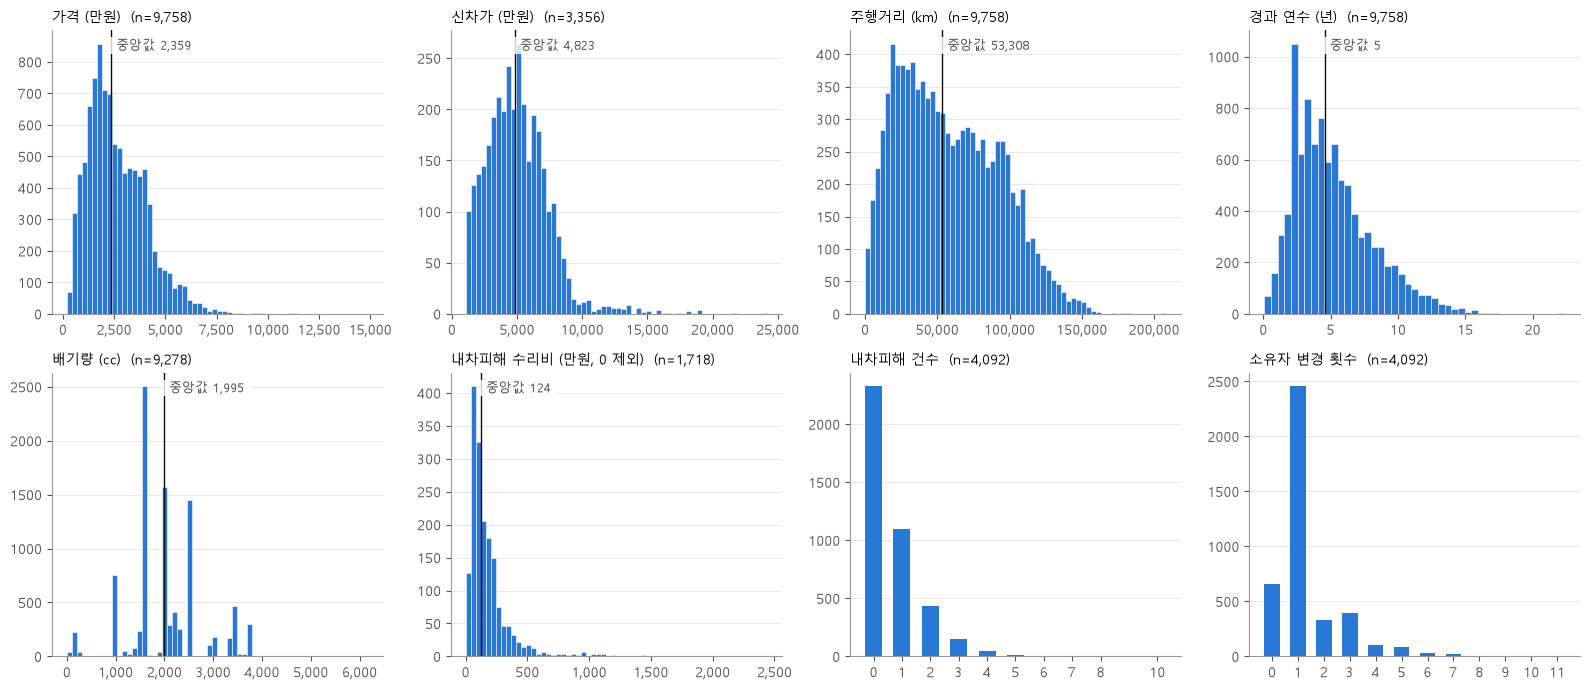

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
panels = [("price", "가격 (만원)", 60, None), ("new_price", "신차가 (만원)", 60, None),
          ("mileage", "주행거리 (km)", 60, None), ("age", "경과 연수 (년)", 45, None),
          ("displacement", "배기량 (cc)", 60, None), ("damage_cost", "내차피해 수리비 (만원, 0 제외)", 60, "positive"),
          ("my_damage", "내차피해 건수", None, None), ("owner_changes", "소유자 변경 횟수", None, None)]
for ax, (col, label, bins, mode) in zip(axes.flat, panels):
    values = cars[col].dropna()
    if mode == "positive":
        values = values[values > 0]
    if bins:
        ax.hist(values, bins=bins, color=BLUE, edgecolor="white", linewidth=0.4)
        ax.axvline(values.median(), color=INK, linewidth=1)
        ax.text(values.median(), ax.get_ylim()[1] * 0.97, f" 중앙값 {values.median():,.0f} ", fontsize=9, color="#52514e", va="top",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1})
    else:
        counts = values.astype(int).value_counts().sort_index()
        ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
        ax.set_xticks(counts.index)
    ax.set_title(f"{label}  (n={len(values):,})", loc="left", fontsize=10)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

값이 한쪽으로 얼마나 치우쳐 있는지(왜도)와, 사분위 범위(IQR) 기준으로 벗어난 값의 수를 본다.
IQR 기준은 `Q1 - 1.5×IQR`보다 작거나 `Q3 + 1.5×IQR`보다 큰 값이다.

In [21]:
def iqr_table(frame, cols):
    rows = {}
    for col in cols:
        v = frame[col].dropna()
        q1, q3 = v.quantile([0.25, 0.75])
        low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        rows[col] = {"건수": len(v), "최솟값": v.min(), "Q1": q1, "중앙값": v.median(), "Q3": q3, "최댓값": v.max(),
                     "왜도": v.skew(), "아래로 벗어남": int((v < low).sum()), "위로 벗어남": int((v > high).sum()),
                     "벗어난 비율": ((v < low) | (v > high)).mean()}
    return pd.DataFrame(rows).T


CONTINUOUS = ["price", "new_price", "mileage", "age", "displacement", "damage_cost"]
iqr_table(cars, CONTINUOUS).style.format("{:,.0f}").format("{:.2f}", subset=["왜도"]).format("{:.1%}", subset=["벗어난 비율"])

,건수,최솟값,Q1,중앙값,Q3,최댓값,왜도,아래로 벗어남,위로 벗어남,벗어난 비율
price,"9,758",189,"1,576","2,359","3,550","14,870",1.07,0,130,1.3%
new_price,"3,356","1,079","3,337","4,823","6,431","24,150",1.42,0,75,2.2%
mileage,"9,758",8,"28,846","53,308","84,131","208,124",0.43,0,4,0.0%
age,"9,758",0,3,5,7,22,0.94,0,204,2.1%
displacement,"9,278",0,"1,598","1,995","2,497","6,162",0.29,301,14,3.4%
damage_cost,"4,087",0,0,0,101,"2,437",4.59,0,308,7.5%


가격·신차가·수리비는 오른쪽 꼬리가 길다. IQR 기준으로 "위로 벗어난" 값이 실제로 무엇인지 가격에서 확인한다.

In [22]:
q1, q3 = cars["price"].quantile([0.25, 0.75])
high = cars[cars["price"] > q3 + 1.5 * (q3 - q1)]
print(f"가격이 IQR 기준 위로 벗어난 매물 {len(high):,}건 (기준 {q3 + 1.5 * (q3 - q1):,.0f}만원 초과)")
print(high["brand"].value_counts().head(8).to_string())
print()
print(high.nlargest(8, "price")[["source", "name", "year", "mileage", "price", "new_price"]].to_string(index=False))

가격이 IQR 기준 위로 벗어난 매물 130건 (기준 6,511만원 초과)
brand
제네시스    65
벤츠      17
테슬라     13
BMW      8
기아       7
포르쉐      7
랜드로버     3
폴스타      2

   source                                                        name   year  mileage   price  new_price
heydealer                                         포르쉐 카이엔 (PO536) 3.0 2024.0   5547.0 14870.0    17590.0
heydealer                                                  포르쉐 타이칸 4S 2025.0   8507.0 14170.0    18010.0
heydealer                                   테슬라 사이버트럭 All-Wheel Drive 2024.0    900.0 13300.0    19110.0
heydealer                                         포르쉐 마칸 일렉트릭 일렉트릭 터보 2025.0   4090.0 12420.0    15830.0
  hyundai 2023 G90 LONG WHEEL BASE 가솔린 3.5 터보 AWD 4인승 시그니처 디자인 셀렉션 카본 2023.0   4262.0 11350.0    18327.0
heydealer                                         로터스 에미라 3.5 퍼스트 에디션 2024.0   6342.0 11225.0    15220.0
     kcar                           랜드로버 레인지로버 스포츠 3세대 P360 HSE 다이나믹  2025.0  37558.0 11050.0        NaN
heydealer              

위로 벗어난 값은 잘못 입력된 값이 아니라 제네시스·수입차 같은 비싼 차다. 차종이 섞인 전체 분포에서 IQR로 자르면 정상인 고가 차만 빠진다.
그래서 이상치는 (1) 값의 뜻으로 보아 말이 안 되는 것(4.2절)과 (2) 같은 모델 안에서 튀는 것(4.3절)으로 나눠서 본다.

### 4.2 규칙에 어긋나는 값

값의 뜻으로 보아 틀렸거나 따로 다뤄야 하는 경우를 규칙으로 센다.

In [23]:
reg_year = cars["first_reg"].dt.year
km_per_year = cars["mileage"] / cars["age"]
plate_ok = cars["plate"].fillna("").str.match(r"^\d{2,3}[가-힣]\d{4}$")
RULES = {
    "가격이 없거나 0 이하": cars["price"].isna() | (cars["price"] <= 0),
    "주행거리가 없거나 0 이하": cars["mileage"].isna() | (cars["mileage"] <= 0),
    "주행거리 100km 미만": cars["mileage"] < 100,
    "주행거리 30만km 초과": cars["mileage"] > 300000,
    "최초등록일이 없거나 수집일 이후": cars["first_reg"].isna() | (cars["first_reg"] > pd.Timestamp(DAY)),
    "연식이 최초등록 연도보다 이름": cars["year"] < reg_year,
    "연식이 최초등록 연도보다 2년 이상 늦음": cars["year"] >= reg_year + 2,
    "연식이 수집 연도보다 큼": cars["year"] > pd.Timestamp(DAY).year,
    "연 4만km 넘게 주행 (등록 1년 이상)": (cars["age"] >= 1) & (km_per_year > 40000),
    "연 1천km 미만 주행 (등록 1년 이상)": (cars["age"] >= 1) & (km_per_year < 1000),
    "가격이 신차가보다 비쌈": cars["price"] > cars["new_price"],
    "가격이 신차가의 15% 미만": cars["price"] < cars["new_price"] * 0.15,
    "내차피해 수리비가 가격보다 큼": cars["damage_cost"] > cars["price"],
    "소유자 변경 6회 이상": cars["owner_changes"] >= 6,
    "전기·수소차인데 배기량이 0보다 큼": cars["fuel"].isin(["전기", "수소"]) & (cars["displacement"] > 0),
    "내연기관차인데 배기량이 600cc 미만": ~cars["fuel"].isin(["전기", "수소"]) & (cars["displacement"] < 600),
    "차량번호 형식이 다름": ~plate_ok,
    "차량번호 중복": cars["plate"].duplicated(keep=False) & cars["plate"].notna(),
}
violations = pd.DataFrame({name: mask.groupby(cars["source"]).sum() for name, mask in RULES.items()}).T[SOURCES]
violations["합계"] = violations.sum(axis=1)
named(violations).style.format("{:,}").background_gradient(cmap="Blues", subset=["합계"], vmin=0)

source,현대 인증,기아 인증,헤이딜러,케이카,합계
가격이 없거나 0 이하,0,0,0,0,0
주행거리가 없거나 0 이하,0,0,0,0,0
주행거리 100km 미만,0,0,0,17,17
주행거리 30만km 초과,0,0,0,0,0
최초등록일이 없거나 수집일 이후,0,0,0,0,0
연식이 최초등록 연도보다 이름,0,8,46,0,54
연식이 최초등록 연도보다 2년 이상 늦음,0,0,0,0,0
연식이 수집 연도보다 큼,0,4,2,18,24
연 4만km 넘게 주행 (등록 1년 이상),3,3,4,9,19
연 1천km 미만 주행 (등록 1년 이상),1,0,3,14,18


건수가 있는 규칙은 실제 매물을 본다.

In [24]:
SHOW = ["source", "name", "year", "first_reg", "mileage", "price", "new_price"]


def examples(rule, cols=SHOW, n=6, sort=None, ascending=True):
    rows = cars[RULES[rule]]
    if sort:
        rows = rows.sort_values(sort, ascending=ascending)
    print(f"[{rule}] {len(rows):,}건")
    print(rows.head(n)[cols].assign(first_reg=lambda d: d["first_reg"].dt.strftime("%Y-%m")).to_string(index=False))
    print()


examples("주행거리 100km 미만", sort="mileage")
examples("연식이 최초등록 연도보다 이름", sort="first_reg", ascending=False)
examples("연식이 수집 연도보다 큼")
examples("연 4만km 넘게 주행 (등록 1년 이상)", sort="mileage", ascending=False)

[주행거리 100km 미만] 17건
source                             name   year first_reg  mileage  price  new_price
  kcar KGM 더 뉴 토레스 가솔린 터보 1.5 2WD 블랙 엣지 2026.0   2026-11      8.0 2990.0        NaN
  kcar KGM 더 뉴 토레스 가솔린 터보 1.5 2WD 블랙 엣지 2026.0   2026-11      9.0 2990.0        NaN
  kcar KGM 더 뉴 토레스 가솔린 터보 1.5 2WD 블랙 엣지 2026.0   2026-11      9.0 2990.0        NaN
  kcar KGM 더 뉴 토레스 가솔린 터보 1.5 2WD 블랙 엣지 2026.0   2026-11     11.0 2990.0        NaN
  kcar KGM 더 뉴 토레스 가솔린 터보 1.5 2WD 블랙 엣지 2026.0   2026-11     12.0 2990.0        NaN
  kcar KGM 더 뉴 토레스 가솔린 터보 1.5 2WD 블랙 엣지 2026.0   2026-11     12.0 2990.0        NaN

[연식이 최초등록 연도보다 이름] 54건
   source                        name   year first_reg  mileage   price  new_price
      kia      EV6 롱레인지 어스 2WD 6 26MY 2025.0   2026-08   6961.0  5547.0        NaN
heydealer   테슬라 사이버트럭 All-Wheel Drive 2024.0   2026-07    900.0 13300.0    19110.0
      kia K5 렌터카 LPi 2.0 프레스티지 7 26MY 2025.0   2026-06   8968.0  2740.0        NaN
      kia K5 렌터카 LPi 2.0 프레스티지 7 26M

In [25]:
examples("가격이 신차가보다 비쌈", sort="price", ascending=False)
examples("가격이 신차가의 15% 미만", sort="price")
examples("내차피해 수리비가 가격보다 큼", cols=["source", "name", "year", "first_reg", "price", "my_damage", "damage_cost", "diag"],
         sort="damage_cost", ascending=False)
examples("소유자 변경 6회 이상", cols=["source", "name", "year", "first_reg", "mileage", "price", "owner_changes"],
         sort="owner_changes", ascending=False)

[가격이 신차가보다 비쌈] 14건
   source                     name   year first_reg  mileage  price  new_price
heydealer 테슬라 모델 Y 주니퍼 L 롱 레인지 AWD 2026.0   2026-06   5773.0 7410.0     6999.0
heydealer     폴스타 폴스타4 롱 레인지 듀얼 모터 2026.0   2025-08   5434.0 7390.0     7190.0
heydealer 테슬라 모델 Y 주니퍼 L 롱 레인지 AWD 2026.0   2026-05   6752.0 7295.0     6999.0
heydealer 테슬라 모델 Y 주니퍼 L 롱 레인지 AWD 2026.0   2026-06  19579.0 7200.0     6999.0
heydealer 테슬라 모델 Y 주니퍼 L 롱 레인지 AWD 2026.0   2026-06   8158.0 7150.0     6999.0
heydealer 테슬라 모델 Y 주니퍼 L 롱 레인지 AWD 2026.0   2026-08   3714.0 7120.0     6999.0

[가격이 신차가의 15% 미만] 21건
   source            name   year first_reg  mileage  price  new_price
heydealer    뉴 SM3 SE 플러스 2014.0   2013-11 147074.0  241.0     1985.0
heydealer   SM3 네오 SE 플러스 2015.0   2014-07 132134.0  265.0     1844.0
heydealer 말리부 2.0 LT 디럭스팩 2013.0   2013-09 100679.0  345.0     2610.0
heydealer    뉴 SM5(신형) LE 2011.0   2010-10 131787.0  360.0     2783.0
heydealer      올 뉴 SM7 RE 2013.0   2013-01 122135.0  37

In [26]:
ev = cars[RULES["전기·수소차인데 배기량이 0보다 큼"]]
print("[전기·수소차인데 배기량이 0보다 큼] 배기량 값 (케이카)")
print(ev["displacement"].astype(int).value_counts().head(8).to_string())
print()
print(ev.head(5)[["source", "name", "fuel", "displacement"]].to_string(index=False))

[전기·수소차인데 배기량이 0보다 큼] 배기량 값 (케이카)
displacement
111    65
180    59
158    20
237    18
133    16
120    16
1      15
196     9

source                     name fuel  displacement
  kcar         현대 코나 일렉트릭 프리미엄    전기         180.0
  kcar    기아 더 뉴 기아 레이 EV 전기 에어   전기         133.0
  kcar 기아 EV3 롱 레인지 2WD GT-line   전기         237.0
  kcar      기아 EV6 롱 레인지 2WD 에어   전기         111.0
  kcar         현대 코나 일렉트릭 프리미엄    전기         180.0


- **주행거리 100km 미만**: 케이카에 같은 모델·같은 가격의 차가 여러 대 있다. 등록만 한 새 차로 보인다. 틀린 값은 아니지만 중고차와 섞으면 주행거리·감가 분석이 흔들린다.
- **연식과 최초등록 연도의 차이**: 연식이 등록 연도보다 1년 빠른 차와, 수집 연도보다 큰 연식(다음 해 연식을 미리 내놓은 차)이 있다. 값이 틀린 것은 아니다.
- **가격이 신차가보다 비쌈**: 헤이딜러의 테슬라 모델 Y, 폴스타 4처럼 최근 연식 차에 몰려 있다. 헤이딜러의 신차가가 옵션을 뺀 기본 가격이면 생길 수 있는 일인데, 원인은 확인하지 못했다.
- **가격이 신차가의 15% 미만**: 10년이 넘은 차다. 값이 틀린 것은 아니다.
- **수리비가 가격보다 큼**, **소유자 변경 6회 이상**: 값은 맞지만 추천에서 따로 알려야 할 매물이다. 모두 헤이딜러 매물이다.
- **전기차의 배기량(케이카)**: 111, 180, 237 같은 숫자가 들어 있다. 배기량일 수 없는 값이고(배터리 용량으로 보인다) 결측으로 바꿔야 한다.

### 4.3 같은 모델·연식 안에서 가격이 튀는 매물

가격이 높은지 낮은지는 같은 차끼리 비교해야 알 수 있다. 먼저 출처마다 다른 모델명을 하나로 맞춘다.

- 현대·기아·케이카가 주는 모델 그룹명("그랜저")을 기준 이름으로 삼는다.
- 같은 브랜드의 기준 이름 중 모델명 안에 들어 있는 가장 긴 이름을 `model_base`로 쓴다 ("아이오닉 5"가 "아이오닉"보다 먼저).
- 맞는 기준 이름이 없으면 괄호와 앞 수식어("더 뉴", "올 뉴")만 뗀 이름을 쓴다.

In [27]:
PREFIX = re.compile(r"^(디\s?올\s?뉴|더\s?올\s?뉴|올\s?뉴|더\s?뉴|뉴|신형|더)\s+")


def squash(name):
    return re.sub(r"[\s\-]", "", re.sub(r"\(.*?\)", "", name)).upper()


vocab = {brand: sorted(set(names.dropna()), key=lambda v: (-len(squash(v)), v))
         for brand, names in cars.groupby("brand")["model_group"]}


def model_base(row):
    if not isinstance(row["model"], str):
        return None
    key = squash(row["model"])
    for name in vocab.get(row["brand"], []):
        if squash(name) in key:
            return name
    s = re.sub(r"\s*\(.*?\)", "", row["model"]).strip()
    while PREFIX.match(s):
        s = PREFIX.sub("", s)
    return s


cars["model_base"] = cars.apply(model_base, axis=1)
in_vocab = cars.apply(lambda r: r["model_base"] in vocab.get(r["brand"], []), axis=1)
matched = in_vocab.groupby(cars["source"]).mean().reindex(SOURCES).rename("기준 이름에 붙은 비율")
print(named(matched.to_frame()).to_string(formatters={"기준 이름에 붙은 비율": "{:.1%}".format}))
print()
print("모델 수:", cars["model"].nunique(), "→ model_base", cars["model_base"].nunique())

       기준 이름에 붙은 비율
source             
현대 인증        100.0%
기아 인증        100.0%
헤이딜러          96.1%
케이카           99.6%

모델 수: 678 → model_base 270


같은 `model_base`·연식 묶음(10대 이상)마다 가격(로그)의 중앙값과 MAD(중앙값에서 떨어진 정도의 중앙값)를 구해,
`|가격 - 중앙값| / (1.4826 × MAD)`가 3.5를 넘는 매물을 튀는 값으로 본다. 평균·표준편차 대신 중앙값·MAD를 쓰는 것은 튀는 값 자체에 기준이 끌려가지 않게 하기 위해서다.

In [28]:
cars["log_price"] = np.log(cars["price"])
group = cars.groupby(["brand", "model_base", "year"])["log_price"]
size, center = group.transform("size"), group.transform("median")
mad = (cars["log_price"] - center).abs().groupby([cars["brand"], cars["model_base"], cars["year"]]).transform("median")
cars["price_z"] = ((cars["log_price"] - center) / (1.4826 * mad)).where((size >= 10) & (mad > 0))
cars["group_median"] = np.exp(center).where(size >= 10)

checked = cars["price_z"].notna()
flagged = cars["price_z"].abs() > 3.5
print(f"비교할 수 있는 매물 {checked.sum():,}건 ({checked.mean():.0%}), 그중 튀는 매물 {flagged.sum():,}건 ({flagged.sum() / checked.sum():.1%})")
print(f"  비싼 쪽 {(cars['price_z'] > 3.5).sum():,}건, 싼 쪽 {(cars['price_z'] < -3.5).sum():,}건")
print()
by = pd.DataFrame({"비교한 매물": checked.groupby(cars["source"]).sum(), "튀는 매물": flagged.groupby(cars["source"]).sum()}).loc[SOURCES]
by["비율"] = by["튀는 매물"] / by["비교한 매물"]
print(named(by).to_string(formatters={"비율": "{:.1%}".format}))

비교할 수 있는 매물 7,537건 (77%), 그중 튀는 매물 122건 (1.6%)
  비싼 쪽 38건, 싼 쪽 84건

        비교한 매물  튀는 매물   비율
source                    
현대 인증     1294     17 1.3%
기아 인증      656     16 2.4%
헤이딜러      1343     22 1.6%
케이카       4244     67 1.6%


In [29]:
VIEW = ["source", "name", "year", "mileage", "price", "group_median", "price_z", "diag"]
fmt = {"mileage": "{:,.0f}".format, "price": "{:,.0f}".format, "group_median": "{:,.0f}".format, "price_z": "{:+.1f}".format}
print("[같은 모델·연식보다 비싼 매물]")
print(cars[flagged].nlargest(8, "price_z")[VIEW].to_string(index=False, formatters=fmt))
print()
print("[같은 모델·연식보다 싼 매물]")
print(cars[flagged].nsmallest(8, "price_z")[VIEW].to_string(index=False, formatters=fmt))

[같은 모델·연식보다 비싼 매물]
   source                               name   year mileage price group_median price_z diag
heydealer   BMW 5시리즈 (G60) 530i xDrive M 스포츠 2024.0  13,166 6,620        4,950   +12.2  무사고
     kcar 벤츠 GLB-클래스 X247 AMG GLB35 4MATIC   2021.0  45,247 3,390        2,785    +7.4  무사고
heydealer                     테슬라 모델 Y 롱 레인지 2024.0  29,307 4,935        3,842    +5.9  무사고
     kcar 벤츠 GLB-클래스 X247 AMG GLB35 4MATIC   2021.0  35,631 3,250        2,785    +5.8 단순수리
heydealer             제네시스 DH G380 프레스티지 AWD 2016.0  36,377 1,830        1,110    +5.6 단순수리
     kcar 벤츠 GLB-클래스 X247 AMG GLB35 4MATIC   2021.0  70,603 3,220        2,785    +5.5  무사고
     kcar     현대 스타리아 디젤 2.2 라운지 2WD 9인승 리무진 2023.0  39,537 4,440        2,380    +5.2  무사고
heydealer                   G70 3.3T 스포츠 AWD 2019.0  36,530 2,830        1,690    +5.2  무사고

[같은 모델·연식보다 싼 매물]
   source                                 name   year mileage price group_median price_z diag
     kcar       기아 더 뉴 쏘렌토 4세대 디젤 2.2 4W

In [30]:
group_km = cars.groupby(["brand", "model_base", "year"])["mileage"].transform("median")
side = pd.Series(np.select([cars["price_z"] > 3.5, cars["price_z"] < -3.5], ["비싼 쪽", "싼 쪽"], "튀지 않음"), index=cars.index)[checked]
profile = pd.DataFrame({
    "매물 수": side.value_counts(),
    "주행거리가 묶음 중앙값보다 많은 비율": (cars["mileage"] > group_km)[checked].groupby(side).mean(),
    "판정이 무사고가 아닌 비율": (cars["diag"] != "무사고")[checked].groupby(side).mean(),
    "LPG·디젤 비율": cars["fuel"].isin(["LPG", "디젤"])[checked].groupby(side).mean(),
    "4WD 비율 (구동방식이 있는 매물)": (cars["drive"] == "4WD").where(cars["drive"].notna())[checked].groupby(side).mean(),
}).loc[["비싼 쪽", "튀지 않음", "싼 쪽"]]
profile.style.format("{:.0%}").format("{:,}", subset=["매물 수"])

,매물 수,주행거리가 묶음 중앙값보다 많은 비율,판정이 무사고가 아닌 비율,LPG·디젤 비율,4WD 비율 (구동방식이 있는 매물)
비싼 쪽,38,26%,16%,8%,44%
튀지 않음,"7,415",49%,38%,16%,30%
싼 쪽,84,81%,36%,33%,31%


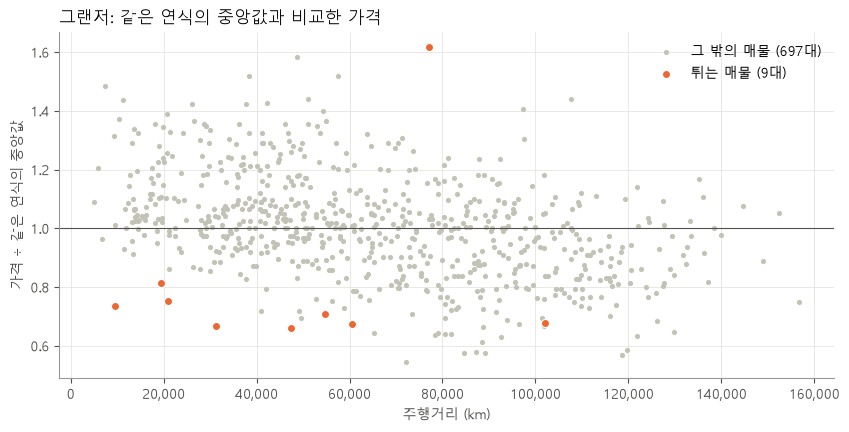

In [31]:
top_model = cars.loc[checked, "model_base"].value_counts().index[0]
one = cars[(cars["model_base"] == top_model) & checked]
fig, ax = plt.subplots(figsize=(10, 4.5))
normal, odd = one[one["price_z"].abs() <= 3.5], one[one["price_z"].abs() > 3.5]
ax.scatter(normal["mileage"], normal["price"] / normal["group_median"], s=14, color=GRAY, linewidths=0,
           label=f"그 밖의 매물 ({len(normal):,}대)")
ax.scatter(odd["mileage"], odd["price"] / odd["group_median"], s=34, color=ORANGE, edgecolors="white", linewidths=0.8,
           label=f"튀는 매물 ({len(odd):,}대)")
ax.axhline(1, color="#52514e", linewidth=0.8)
ax.set_xlabel("주행거리 (km)")
ax.set_ylabel("가격 ÷ 같은 연식의 중앙값")
ax.set_title(f"{top_model}: 같은 연식의 중앙값과 비교한 가격", loc="left")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False)
plt.show()

튀는 매물에는 두 종류가 섞여 있다.

- **비싼 쪽**은 같은 모델 이름 아래의 다른 차다. 위 목록의 AMG, M 스포츠, 3.3T, 리무진처럼 고성능 모델이나 상위 트림이고, `model_base`는 이 차이를 구분하지 못한다.
- **싼 쪽**은 같은 묶음의 다른 차보다 주행거리가 많은 차, LPG·디젤처럼 값이 낮은 등급의 차가 많다(위 표).

가격이 잘못 입력된 것으로 보이는 매물은 없다. 지울 값이 아니라, 비교 단위(모델)를 등급까지 나누거나 주행거리를 함께 봐야 설명되는 값이다.

## 5. 컬럼 간 관계

### 5.1 수치 컬럼 사이의 상관

값의 분포가 한쪽으로 치우쳐 있어 순위 상관(Spearman)을 쓴다. 두 컬럼이 모두 있는 매물만 계산한다.

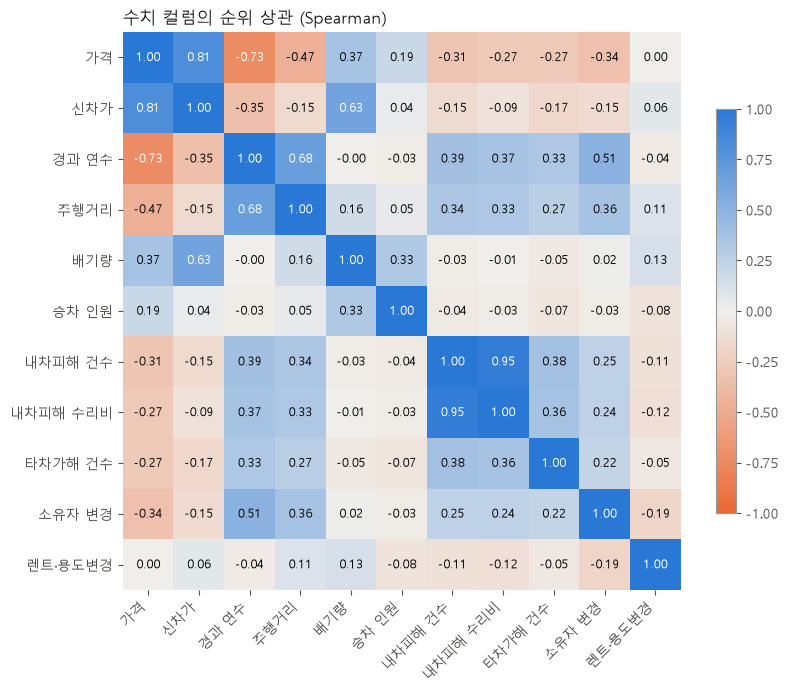

In [32]:
CORR = ["price", "new_price", "age", "mileage", "displacement", "seats", "my_damage", "damage_cost", "other_damage", "owner_changes", "rent_use"]
LABEL = {"price": "가격", "new_price": "신차가", "age": "경과 연수", "mileage": "주행거리", "displacement": "배기량", "seats": "승차 인원",
         "my_damage": "내차피해 건수", "damage_cost": "내차피해 수리비", "other_damage": "타차가해 건수",
         "owner_changes": "소유자 변경", "rent_use": "렌트·용도변경"}


def heatmap(matrix, title, cmap=DIVERGING, vmin=-1, vmax=1, fmt="{:.2f}", figsize=(9, 7.5)):
    fig, ax = plt.subplots(figsize=figsize)
    image = ax.imshow(matrix.values, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(matrix.shape[0]), matrix.index)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            v = matrix.values[i, j]
            if not np.isnan(v):
                dark = abs(v) > 0.6 if vmin < 0 else v > vmin + (vmax - vmin) * 0.6
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if dark else INK)
    ax.set_title(title, loc="left")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(image, ax=ax, shrink=0.7)
    plt.show()


corr = cars[CORR].corr(method="spearman").rename(index=LABEL, columns=LABEL)
heatmap(corr, "수치 컬럼의 순위 상관 (Spearman)")

In [33]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("상관").reset_index()
pairs.columns = ["컬럼 A", "컬럼 B", "상관"]
pairs["함께 있는 매물"] = [cars[[a, b]].dropna().shape[0] for a, b in
                      zip(pairs["컬럼 A"].map({v: k for k, v in LABEL.items()}), pairs["컬럼 B"].map({v: k for k, v in LABEL.items()}))]
strong = pairs[pairs["상관"].abs() >= 0.3].sort_values("상관", key=abs, ascending=False)
strong.style.format({"상관": "{:+.2f}", "함께 있는 매물": "{:,}"}).hide(axis="index")

컬럼 A,컬럼 B,상관,함께 있는 매물
내차피해 건수,내차피해 수리비,+0.95,"4,087"
가격,신차가,+0.81,"3,356"
가격,경과 연수,-0.73,"9,758"
경과 연수,주행거리,+0.68,"9,758"
신차가,배기량,+0.63,"2,973"
경과 연수,소유자 변경,+0.51,"4,092"
가격,주행거리,-0.47,"9,758"
경과 연수,내차피해 건수,+0.39,"4,092"
내차피해 건수,타차가해 건수,+0.38,"4,092"
경과 연수,내차피해 수리비,+0.37,"4,087"


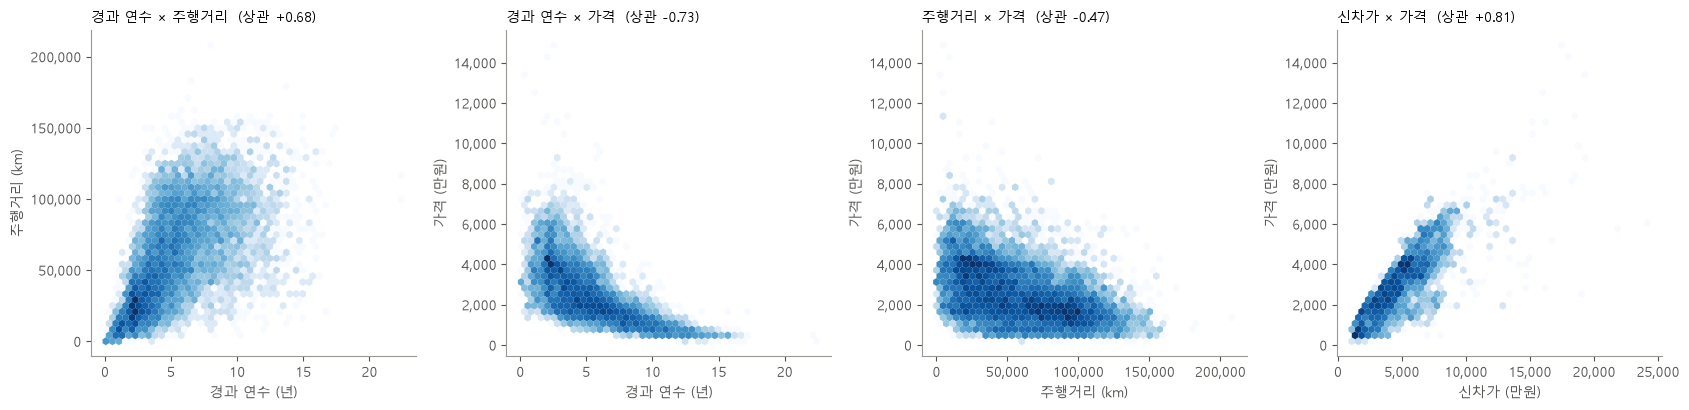

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
plots = [("age", "mileage", "경과 연수 (년)", "주행거리 (km)"), ("age", "price", "경과 연수 (년)", "가격 (만원)"),
         ("mileage", "price", "주행거리 (km)", "가격 (만원)"), ("new_price", "price", "신차가 (만원)", "가격 (만원)")]
for ax, (x, y, xlabel, ylabel) in zip(axes, plots):
    both = cars[[x, y]].dropna()
    ax.hexbin(both[x], both[y], gridsize=45, cmap="Blues", mincnt=1, bins="log", linewidths=0)
    rho = both.corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{xlabel.split(' (')[0]} × {ylabel.split(' (')[0]}  (상관 {rho:+.2f})", loc="left", fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(False)
plt.tight_layout()
plt.show()

색이 진할수록 매물이 많이 몰린 곳이다.

### 5.2 모델을 고정하면 관계가 달라진다

전체에서 본 상관에는 "어떤 차인가"의 차이가 섞여 있다. 비싼 차와 싼 차가 한데 섞이면 주행거리와 가격의 관계가 흐려진다.
같은 `model_base` 안에서(모델별 중앙값을 뺀 값으로) 다시 계산해 비교한다. 매물이 30대 이상인 모델만 쓴다.

In [35]:
big = cars.groupby(["brand", "model_base"])["id"].transform("size") >= 30
inner = cars[big].copy()
WITHIN = ["log_price", "age", "mileage", "my_damage", "damage_cost", "owner_changes", "rent_use"]
keys = [inner["brand"], inner["model_base"]]
centered = inner[WITHIN] - inner[WITHIN].groupby(keys).transform("median")

compare = pd.DataFrame({
    "전체에서 본 상관": cars[WITHIN].corr(method="spearman")["log_price"],
    "같은 모델 안에서 본 상관": centered.corr(method="spearman")["log_price"],
}).drop(index="log_price").rename(index=LABEL)
print(f"모델 {inner.groupby(['brand', 'model_base']).ngroups}종, 매물 {len(inner):,}대")
compare.style.format("{:+.2f}").background_gradient(cmap=DIVERGING, vmin=-1, vmax=1)

모델 53종, 매물 8,513대


,전체에서 본 상관,같은 모델 안에서 본 상관
경과 연수,-0.73,-0.87
주행거리,-0.47,-0.72
내차피해 건수,-0.31,-0.28
내차피해 수리비,-0.27,-0.25
소유자 변경,-0.34,-0.35
렌트·용도변경,+0.00,-0.05


- 경과 연수·주행거리와 가격의 관계는 모델을 고정하면 더 뚜렷해진다.
- 내차피해·소유자 변경과 가격의 상관은 모델을 고정해도 -0.3 안팎이다. 오래된 차일수록 사고와 소유자 변경이 많기 때문에(5.1절), 이 값에는 연식의 영향이 섞여 있다.
- 렌트·용도변경 이력은 가격과 거의 관계가 없다.

### 5.3 범주 컬럼과 가격

범주 컬럼 하나가 가격(로그)의 흩어짐을 얼마나 설명하는지 상관비(η²)로 본다. 0이면 범주에 따라 가격이 달라지지 않고, 1이면 범주만 알면 가격이 정해진다.

In [36]:
def eta_squared(frame, by, value="log_price"):
    sub = frame[[by, value]].dropna()
    if sub[by].nunique() < 2:
        return np.nan
    total = ((sub[value] - sub[value].mean()) ** 2).sum()
    within = sub.groupby(by)[value].transform(lambda s: (s - s.mean()) ** 2).sum()
    return 1 - within / total


cars["source_name"] = cars["source"].map(SOURCE_NAME)
CAT = {"source_name": "출처", "brand": "브랜드", "model_base": "모델 (model_base)", "fuel": "연료", "body": "차종",
       "transmission": "변속기", "drive": "구동방식", "color": "색", "region": "지역", "diag": "성능점검 판정"}
eta = pd.DataFrame({
    "값 종류 수": {label: cars[col].nunique() for col, label in CAT.items()},
    "값이 있는 매물": {label: cars[col].notna().sum() for col, label in CAT.items()},
    "η² (전체)": {label: eta_squared(cars, col) for col, label in CAT.items()},
}).sort_values("η² (전체)", ascending=False)
eta.style.format({"값 종류 수": "{:,}", "값이 있는 매물": "{:,}", "η² (전체)": "{:.2f}"}).bar(subset=["η² (전체)"], color="#a9c8ee", vmin=0, vmax=1)

,값 종류 수,값이 있는 매물,η² (전체)
모델 (model_base),270,"9,758",0.66
색,460,"9,758",0.41
차종,15,"7,726",0.32
브랜드,32,"9,758",0.28
지역,16,"7,726",0.21
구동방식,2,"3,462",0.19
출처,4,"9,758",0.14
연료,6,"9,758",0.14
성능점검 판정,3,"9,758",0.10
변속기,3,"9,639",0.00


가격을 가장 많이 설명하는 범주는 모델이다. 색은 값 종류가 매우 많고 제조사 색 이름이 브랜드·모델마다 달라서, 색 자체보다 "어느 차인가"를 대신 가리키는 값으로 봐야 한다.
변속기는 거의 전부 자동이라 가격을 설명하지 못한다.

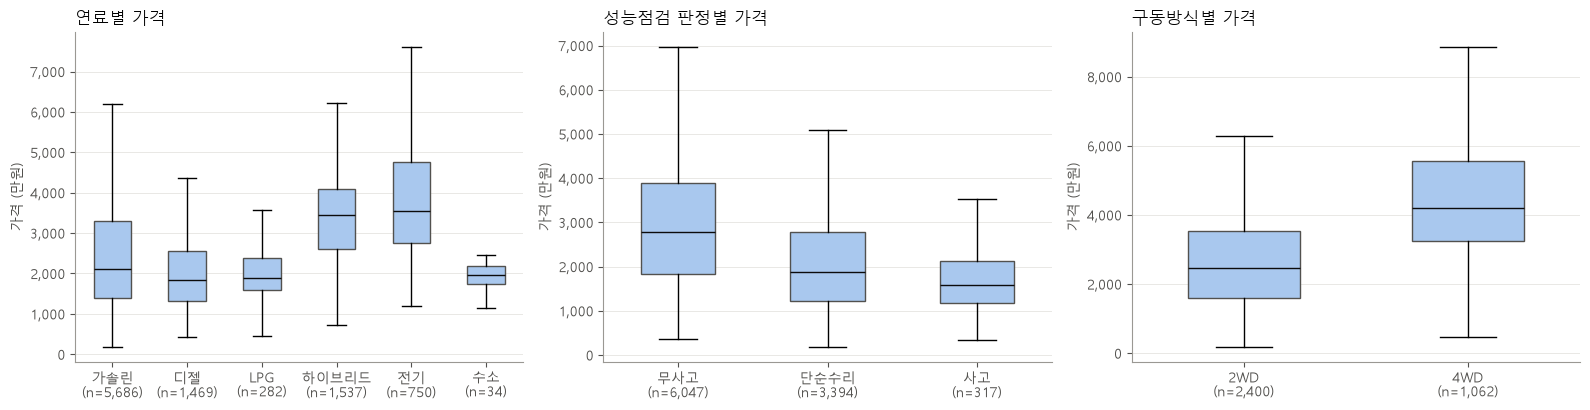

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, title, order) in zip(axes, [
        ("fuel", "연료별 가격", ["가솔린", "디젤", "LPG", "하이브리드", "전기", "수소"]),
        ("diag", "성능점검 판정별 가격", ["무사고", "단순수리", "사고"]),
        ("drive", "구동방식별 가격", ["2WD", "4WD"])]):
    data = [cars.loc[cars[col] == v, "price"].dropna() for v in order]
    bp = ax.boxplot(data, tick_labels=[f"{v}\n(n={len(d):,})" for v, d in zip(order, data)], showfliers=False,
                    patch_artist=True, widths=0.5)
    for patch in bp["boxes"]:
        patch.set_facecolor("#a9c8ee")
        patch.set_edgecolor("#52514e")
    for median in bp["medians"]:
        median.set_color(INK)
    ax.set_title(title, loc="left")
    ax.set_ylabel("가격 (만원)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

상자 그림은 벗어난 점을 빼고 그렸다. 판정별 가격은 "사고" 판정이 케이카에만 있어서 출처의 차이가 섞여 있다(5.4절).

### 5.4 범주 컬럼끼리의 관계

두 범주 컬럼이 얼마나 함께 움직이는지 Cramér의 V로 본다. 0이면 관계가 없고, 1이면 한쪽을 알면 다른 쪽이 정해진다.

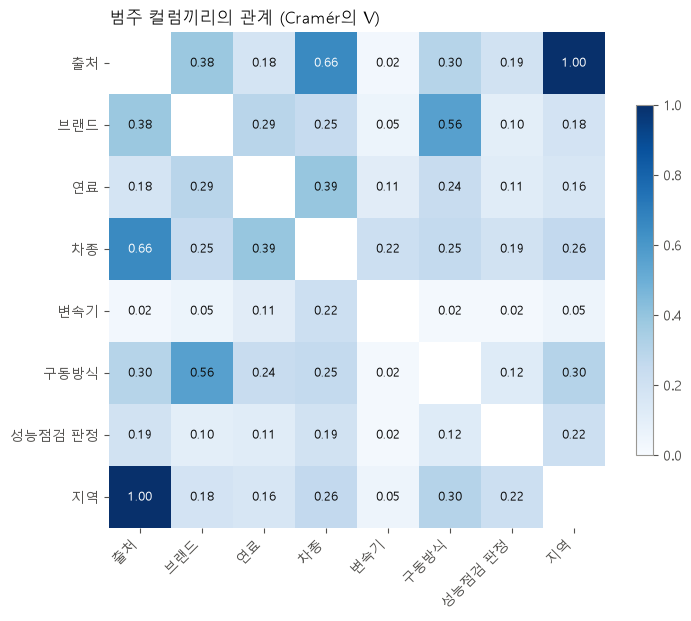

In [38]:
def cramers_v(a, b):
    table = pd.crosstab(a, b).values.astype(float)
    if min(table.shape) < 2:
        return np.nan
    n = table.sum()
    expected = table.sum(axis=1, keepdims=True) @ table.sum(axis=0, keepdims=True) / n
    chi2 = ((table - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


PAIR = {"source_name": "출처", "brand": "브랜드", "fuel": "연료", "body": "차종", "transmission": "변속기",
        "drive": "구동방식", "diag": "성능점검 판정", "region": "지역"}
v = pd.DataFrame([[cramers_v(cars[a], cars[b]) if a != b else np.nan for b in PAIR] for a in PAIR],
                 index=PAIR.values(), columns=PAIR.values())
heatmap(v, "범주 컬럼끼리의 관계 (Cramér의 V)", cmap="Blues", vmin=0, vmax=1, figsize=(8, 6.5))

In [39]:
print("[출처 × 브랜드 (상위 8개 브랜드)]")
top_brands = cars["brand"].value_counts().index[:8]
print(named(pd.crosstab(cars["brand"], cars["source"]).loc[top_brands, SOURCES]).to_string())
print()
print("[출처 × 성능점검 판정] 행 기준 비율")
print(named(pd.crosstab(cars["source"], cars["diag"], normalize="index").loc[SOURCES, ["무사고", "단순수리", "사고"]]).to_string(
    float_format="{:.1%}".format))
print()
print("[출처 × 연료] 행 기준 비율")
print(named(pd.crosstab(cars["source"], cars["fuel"], normalize="index").loc[SOURCES]).to_string(float_format="{:.1%}".format))

[출처 × 브랜드 (상위 8개 브랜드)]
source     현대 인증  기아 인증  헤이딜러   케이카
brand                              
현대           777      0   619  1841
기아             0    733   484  1844
제네시스         550      0   139   524
KGM            0      0    61   329
르노코리아(삼성)      0      0   110   229
벤츠             0      0   130   185
쉐보레(GM대우)      0      0   101   175
BMW            0      0    81   172

[출처 × 성능점검 판정] 행 기준 비율
diag      무사고  단순수리   사고
source                  
현대 인증   56.4% 43.6% 0.0%
기아 인증  100.0%  0.0% 0.0%
헤이딜러    66.8% 33.2% 0.0%
케이카     56.6% 37.8% 5.6%

[출처 × 연료] 행 기준 비율
fuel    LPG   가솔린    디젤   수소    전기  하이브리드
source                                   
현대 인증  0.8% 69.6%  0.2% 0.0%  8.4%  21.1%
기아 인증  1.2% 31.0% 15.7% 0.0% 13.2%  38.9%
헤이딜러   2.5% 53.4% 17.6% 0.6% 13.3%  12.5%
케이카    3.7% 60.9% 17.6% 0.4%  4.8%  12.7%


- **출처 ↔ 지역·차종**: 가장 강하게 묶여 있다. 지역과 차종은 출처마다 표기가 달라서(6.3절), 값만 보면 어느 출처인지 알 수 있을 정도다. 차의 차이가 아니라 표기의 차이다.
- **출처 ↔ 브랜드**: 인증 중고차는 자기 브랜드만 판다.
- **출처 ↔ 성능점검 판정**: V는 낮지만 판정의 구성이 출처마다 다르다. "사고" 판정은 케이카에만 있고, 기아는 전부 "무사고"다.
- **브랜드 ↔ 구동방식**, **연료 ↔ 차종**: 브랜드와 차급에 따라 4WD 비율과 연료 구성이 다르다.

출처가 다른 매물을 비교할 때 차종·지역·판정의 차이는 차의 차이가 아니라 출처의 차이일 수 있다.

### 5.5 서로 겹치는 컬럼

같은 정보를 담은 컬럼끼리는 한쪽이 비었을 때 다른 쪽으로 채울 수 있다.

In [40]:
print("[연식 - 최초등록 연도] 연식으로 등록 연도를 얼마나 맞힐 수 있나")
gap = (cars["year"] - cars["first_reg"].dt.year).astype(int)
print(pd.crosstab(cars["source"], gap, normalize="index").loc[SOURCES].rename(index=SOURCE_NAME).to_string(float_format="{:.1%}".format))
print()
print("[성능점검 판정 × 보험 내차피해] 판정별로 내차피해가 1건 이상인 비율")
has = cars.dropna(subset=["my_damage"])
cross = (has["my_damage"] > 0).groupby([has["source"], has["diag"]]).agg(["mean", "size"])
cross.columns = ["내차피해 있음", "매물 수"]
print(cross.rename(index=SOURCE_NAME, level=0).to_string(formatters={"내차피해 있음": "{:.0%}".format}))

[연식 - 최초등록 연도] 연식으로 등록 연도를 얼마나 맞힐 수 있나
col_0    -2   -1      0     1
source                       
현대 인증  0.0% 0.0% 100.0%  0.0%
기아 인증  0.0% 1.1%  49.1% 49.8%
헤이딜러   0.0% 2.2%  59.4% 38.3%
케이카    0.0% 0.0%  62.7% 37.3%

[성능점검 판정 × 보험 내차피해] 판정별로 내차피해가 1건 이상인 비율
            내차피해 있음  매물 수
source diag              
헤이딜러   단순수리     79%   674
       무사고      38%  1358
현대 인증  단순수리     58%   579
       무사고      27%   748
기아 인증  무사고      25%   733


In [41]:
has_new = cars.dropna(subset=["new_price"])
spread = has_new.groupby(["source", "brand", "model_base", "grade", "trim"], dropna=False)["new_price"].agg(["size", "median", "std"])
spread = spread[spread["size"] >= 5]
spread["변동계수"] = spread["std"] / spread["median"]
print(f"[같은 출처·모델·등급·트림 안에서 신차가가 얼마나 같은가] 5대 이상인 묶음 {len(spread):,}개")
print(spread["변동계수"].describe(percentiles=[0.5, 0.9]).rename({"50%": "중앙값", "90%": "90% 분위"}).loc[["중앙값", "90% 분위", "max"]].to_string(
    float_format="{:.1%}".format))
print()
loose = has_new.groupby(["brand", "model_base"])["new_price"].agg(["size", "median", "std"])
loose = loose[loose["size"] >= 5]
print(f"[같은 모델 안에서만 묶으면] 묶음 {len(loose):,}개, 변동계수 중앙값 {(loose['std'] / loose['median']).median():.1%}")

[같은 출처·모델·등급·트림 안에서 신차가가 얼마나 같은가] 5대 이상인 묶음 176개
중앙값       3.7%
90% 분위    7.5%
max      12.3%

[같은 모델 안에서만 묶으면] 묶음 75개, 변동계수 중앙값 12.4%


- **연식 ↔ 최초등록 연도**: 거의 같거나 1년 차이다. 등록일이 비면 연식으로 연도까지는 채울 수 있다.
- **성능점검 판정 ↔ 보험 내차피해**: 겹치지만 같은 말은 아니다. 판정이 "무사고"여도 보험 수리 이력이 있는 매물이 적지 않아서, 한쪽으로 다른 쪽을 대신 채울 수는 없다.
- **신차가 ↔ 모델·등급·트림**: 같은 등급·트림이면 신차가가 거의 같다(옵션 차이만큼만 다르다). 모델만 같을 때는 차이가 크다.

## 6. 결측치·이상치 처리

### 6.1 결측치 처리 방법

3절에서 나눈 결측의 종류에 따라 처리한다.

| 컬럼 | 결측 | 종류 | 처리 | 확인 |
|---|---|---|---|---|
| model_group | 헤이딜러 전체 | 출처가 주지 않음 | `model`에서 기준 이름을 찾아 `model_base`로 채움 | 4.3절 |
| body | 헤이딜러 전체 | 출처가 주지 않음 | 같은 모델의 다른 출처 차종으로 채움 | 아래 (가) |
| new_price | 기아·케이카 전체, 헤이딜러 몇 건 | 출처가 주지 않음 | 현대·헤이딜러의 같은 모델·연료 신차가 중앙값으로 채우고 "추정값"으로 표시. 못 채우면 비워 둠 | 아래 (나) |
| drive | 케이카 전체 | 출처가 주지 않음 | 차 이름에 적힌 "2WD/4WD/AWD"에서 뽑음. 이름에 없으면 비워 둠 | 아래 (다) |
| drive | 기아 일부 | 조건에 따라 빔 | 2WD로 채움 (4WD일 때만 적는 표기) | 3.3절 |
| displacement, transmission | 전기·수소차 | 조건에 따라 빔 | 비워 둠 ("해당 없음"). 0이나 다른 숫자가 들어 있으면 결측으로 바꿈 | 3.3절, 4.2절 |
| trim | 헤이딜러·케이카 일부 | 조건에 따라 빔 | 비워 두고, 묶을 때는 `grade`를 대신 씀 | 3.3절 |
| seats, region | 헤이딜러 전체 | 출처가 주지 않음 | 비워 둠. 승차 인원은 제원 DB에서 채울 수 있음 | - |
| my_damage, damage_cost, other_damage, owner_changes, rent_use | 케이카 전체 | 출처가 주지 않음 | 비워 두고 "정보 없음"으로 표시. 0으로 채우지 않음 | 아래 (라) |
| damage_cost | 내차피해는 있는데 0이거나 없음 | 0이 결측을 가림 | 결측으로 바꿈 | 3.5절 |

보험 이력을 0으로 채우지 않는 이유는, 0이면 "사고 없음"이 되어 케이카 매물이 전부 무사고 매물로 취급되기 때문이다.

**(가) 차종을 모델로 채울 수 있나.** 케이카 매물에서 모델마다 가장 많은 차종을 그 모델의 차종으로 정했을 때, 실제 차종과 얼마나 맞는지와 다른 출처 매물을 얼마나 채울 수 있는지 본다.

In [42]:
kc = cars[cars["source"] == "kcar"]
major = kc.groupby(["brand", "model_base"])["body"].agg(lambda s: s.value_counts().index[0]).rename("body_filled")
agree = kc.join(major, on=["brand", "model_base"])
print(f"케이카: 모델의 대표 차종과 실제 차종이 같은 매물 {(agree['body'] == agree['body_filled']).mean():.1%}")
mixed = kc.groupby(["brand", "model_base"])["body"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print(f"  차종이 둘 이상 섞인 모델 {(mixed < 1).sum()}종 / {len(mixed)}종")
print()
cover = cars.join(major, on=["brand", "model_base"])["body_filled"].notna().groupby(cars["source"]).mean().reindex(SOURCES)
print("케이카의 모델별 차종으로 채울 수 있는 비율")
print(named(cover.rename("채울 수 있는 비율").to_frame()).to_string(formatters={"채울 수 있는 비율": "{:.1%}".format}))

케이카: 모델의 대표 차종과 실제 차종이 같은 매물 98.8%

  차종이 둘 이상 섞인 모델 7종 / 217종

케이카의 모델별 차종으로 채울 수 있는 비율
       채울 수 있는 비율
source           
현대 인증      100.0%
기아 인증       93.0%
헤이딜러        96.2%
케이카        100.0%


**(나) 신차가를 같은 차의 신차가로 채울 수 있나.** 신차가가 있는 현대·헤이딜러 매물을 다섯 묶음으로 나눠, 한 묶음의 신차가를 가리고 나머지 묶음의 같은 조건 중앙값으로 맞혀 본다.
조건을 잘게 나눌수록 정확해지지만 맞는 상대가 없는 매물이 늘어난다.

In [43]:
donor = cars.dropna(subset=["new_price"]).reset_index(drop=True)
fold = np.random.default_rng(0).permutation(len(donor)) % 5
target = cars[cars["source"].isin(["kia", "kcar"])]


def fill_check(keys):
    predicted = pd.Series(np.nan, index=donor.index)
    for f in range(5):
        median = donor[fold != f].groupby(keys)["new_price"].median().rename("predicted").reset_index()
        test = donor[fold == f]
        predicted[test.index] = test[keys].merge(median, on=keys, how="left")["predicted"].values
    error = (predicted / donor["new_price"] - 1).abs()
    known = donor[keys].drop_duplicates().assign(found=True)
    return {"가려 놓고 맞힌 비율": predicted.notna().mean(), "오차 중앙값": error.median(), "오차 90% 분위": error.quantile(0.9),
            "기아에서 채울 수 있는 비율": target[target["source"] == "kia"][keys].merge(known, on=keys, how="left")["found"].notna().mean(),
            "케이카에서 채울 수 있는 비율": target[target["source"] == "kcar"][keys].merge(known, on=keys, how="left")["found"].notna().mean()}


options = {"모델": ["brand", "model_base"], "모델 + 연료": ["brand", "model_base", "fuel"],
           "모델 + 연료 + 연식": ["brand", "model_base", "fuel", "year"]}
pd.DataFrame({name: fill_check(keys) for name, keys in options.items()}).T.style.format("{:.1%}")

,가려 놓고 맞힌 비율,오차 중앙값,오차 90% 분위,기아에서 채울 수 있는 비율,케이카에서 채울 수 있는 비율
모델,97.7%,9.1%,25.8%,91.8%,96.0%
모델 + 연료,96.6%,7.1%,19.2%,88.4%,93.0%
모델 + 연료 + 연식,86.8%,5.0%,15.6%,46.5%,74.3%


In [44]:
common = donor.groupby(["brand", "model_base", "fuel", "year", "source"])["new_price"].median().unstack("source").dropna()
ratio = common["hyundai"] / common["heydealer"]
print(f"현대 인증과 헤이딜러에 모두 있는 모델·연료·연식 {len(common)}개에서 신차가 중앙값의 비 (현대 ÷ 헤이딜러)")
print(ratio.describe(percentiles=[0.1, 0.5, 0.9]).loc[["10%", "50%", "90%"]].to_string(float_format="{:.2f}".format))

현대 인증과 헤이딜러에 모두 있는 모델·연료·연식 98개에서 신차가 중앙값의 비 (현대 ÷ 헤이딜러)
10%   0.90
50%   1.00
90%   1.11


- 조건을 "모델 + 연료"로 두면 기아·케이카 매물 대부분을 채울 수 있고, 가려 놓고 맞혔을 때의 오차는 위 표와 같다. 연식까지 맞추면 오차는 줄지만 채울 수 있는 매물이 크게 준다.
- 남는 오차는 같은 모델 안의 등급·트림·옵션 차이다(5.5절). 등급까지 맞추려면 출처마다 다른 등급 표기를 먼저 맞춰야 한다.
- 현대 인증과 헤이딜러의 신차가는 같은 모델·연료·연식에서 중앙값이 거의 같다. 두 출처의 값을 함께 써도 한쪽으로 치우치지 않는다.
- 채운 값은 실제 값이 아니므로 감가율처럼 신차가를 쓰는 계산에서는 추정값임을 구분해야 한다.

**(다) 구동방식을 차 이름에서 뽑을 수 있나.** 구동방식이 있는 현대·헤이딜러에서 이름에 적힌 값과 실제 값이 맞는지 보고, 케이카에서 몇 건을 채울 수 있는지 센다.

In [45]:
token = cars["name"].str.upper().str.extract(r"(4WD|AWD|2WD)")[0]
from_name = token.map({"4WD": "4WD", "AWD": "4WD", "2WD": "2WD"})
check = pd.DataFrame({
    "이름에 구동방식이 있는 비율": from_name.notna().groupby(cars["source"]).mean(),
    "이름과 실제 값이 같은 비율": (from_name == cars["drive"]).where(from_name.notna() & cars["drive"].notna()).groupby(cars["source"]).mean(),
}).loc[SOURCES]
print(named(check).to_string(float_format="{:.1%}".format, na_rep="-"))
print()
kcar_names = cars.loc[(cars["source"] == "kcar") & from_name.isna(), "name"]
print("케이카에서 이름에 구동방식이 없는 매물의 예:", kcar_names.sample(5, random_state=0).tolist())

        이름에 구동방식이 있는 비율 이름과 실제 값이 같은 비율
source                                 
현대 인증             81.0%          100.0%
기아 인증             52.8%          100.0%
헤이딜러              34.1%          100.0%
케이카               42.1%               -

케이카에서 이름에 구동방식이 없는 매물의 예: ['르노코리아(삼성) SM3 네오 LE ', '현대 더 뉴 아반떼 (CN7) 가솔린 1.6 인스퍼레이션', '기아 더 뉴 기아 레이 시그니처 ', '벤츠 GLB-클래스 X247 AMG GLB35 4MATIC  ', '기아 K5 3세대 가솔린 2.0 노블레스']


이름에 구동방식이 적힌 경우에는 실제 값과 모두 같다. 다만 이름에 적히지 않은 매물이 많아 케이카의 일부만 채울 수 있다.
이름에 없는 매물은 세단처럼 2WD뿐인 차와 "4MATIC", "xDrive"처럼 브랜드 고유 이름으로 적힌 4WD가 섞여 있어, 2WD로 일괄해서 채울 수는 없다.

**(라) 케이카의 보험 이력.** 목록 화면만 수집해서 없다. 상세 화면을 수집하기 전에는 성능점검 판정(`diag`)만 쓸 수 있다.
원본의 "보험이력없음" 표시(3.5절)는 표시가 붙은 매물에 한해 `my_damage = 0`으로 볼 수 있다.

### 6.2 이상치 처리 방법

4절에서 본 것처럼 가격이 잘못 입력된 매물은 찾지 못했다. 지우는 대신 값을 고치거나 표시를 붙인다.

| 경우 | 처리 | 이유 |
|---|---|---|
| 가격·주행거리·최초등록일이 없거나 0 이하 | 매물 제외 | 순위를 매길 수 없음. 이번 데이터에는 없음 |
| 차량번호 중복 | 한 건만 남김 | 같은 차. 이번 데이터에는 없음 |
| 주행거리 100km 미만 | `새 차` 표시 | 값은 맞지만 중고차와 성격이 다름. 감가·적정가 계산에서 제외 |
| 전기·수소차의 배기량에 값이 있음, 배기량 0 | 배기량을 결측으로 | 배기량이 아닌 값, "해당 없음"을 0으로 적은 값 |
| 내차피해는 있는데 수리비가 0 | 수리비를 결측으로 | 금액을 모르는 것 |
| 가격이 신차가보다 비쌈 | 값 유지 | 최근 연식 차에서 실제로 생김. 감가율을 쓸 때는 1을 넘지 않게 자름 |
| 수리비가 가격보다 큼, 소유자 변경 6회 이상, 연 4만km 넘게 주행 | 값 유지, `주의` 표시 | 값은 맞고, 추천할 때 알려야 할 정보 |
| 같은 모델·연식 안에서 가격이 튐 | 값 유지, 표시 | 트림·주행거리·사고로 설명되는 차이. 적정가를 구할 때는 중앙값처럼 튀는 값에 덜 끌리는 방법을 씀 |
| 전체 분포에서 IQR을 벗어남 | 처리하지 않음 | 비싼 차일 뿐임 (4.1절) |

아래는 이 처리를 적용했을 때 바뀌는 건수다.

In [46]:
clean = cars.copy()
drop = RULES["가격이 없거나 0 이하"] | RULES["주행거리가 없거나 0 이하"] | RULES["최초등록일이 없거나 수집일 이후"]
duplicate = clean["plate"].duplicated(keep="first") & clean["plate"].notna()
clean = clean[~drop & ~duplicate].copy()

clean["is_new_car"] = clean["mileage"] < 100
ev_displacement = (clean["fuel"].isin(["전기", "수소"]) & clean["displacement"].notna()) | (clean["displacement"] == 0)
clean.loc[ev_displacement, "displacement"] = np.nan
unknown_cost = (clean["my_damage"] > 0) & (clean["damage_cost"] == 0)
clean.loc[unknown_cost, "damage_cost"] = np.nan
kia_2wd = (clean["source"] == "kia") & clean["drive"].isna() & clean["transmission"].notna()
clean.loc[kia_2wd, "drive"] = "2WD"
name_drive = clean["name"].str.upper().str.extract(r"(4WD|AWD|2WD)")[0].map({"4WD": "4WD", "AWD": "4WD", "2WD": "2WD"})
kcar_drive = (clean["source"] == "kcar") & name_drive.notna()
clean.loc[kcar_drive, "drive"] = name_drive[kcar_drive]
clean["body_filled"] = clean["body"].fillna(clean.join(major, on=["brand", "model_base"])["body_filled"])
clean["caution"] = ((clean["damage_cost"] > clean["price"]) | (clean["owner_changes"] >= 6)
                    | ((clean["age"] >= 1) & (clean["mileage"] / clean["age"] > 40000)))
clean["price_outlier"] = clean["price_z"].abs() > 3.5

applied = pd.DataFrame({
    "처리 전 매물": cars.groupby("source").size(),
    "제외": (drop | (cars["plate"].duplicated(keep="first") & cars["plate"].notna())).groupby(cars["source"]).sum(),
    "새 차 표시": clean["is_new_car"].groupby(clean["source"]).sum(),
    "배기량 → 결측": ev_displacement.groupby(clean["source"]).sum(),
    "수리비 → 결측": unknown_cost.groupby(clean["source"]).sum(),
    "구동방식 채움": (kia_2wd | kcar_drive).groupby(clean["source"]).sum(),
    "차종 채움": (clean["body"].isna() & clean["body_filled"].notna()).groupby(clean["source"]).sum(),
    "주의 표시": clean["caution"].groupby(clean["source"]).sum(),
    "가격 튐 표시": clean["price_outlier"].groupby(clean["source"]).sum(),
}).loc[SOURCES]
applied.loc["합계"] = applied.sum()
named(applied).style.format("{:,.0f}")

,처리 전 매물,제외,새 차 표시,배기량 → 결측,수리비 → 결측,구동방식 채움,차종 채움,주의 표시,가격 튐 표시
source,,,,,,,,,
현대 인증,"1,327",0,0,0,34,0,0,3,17
기아 인증,733,0,0,0,0,630,0,3,16
헤이딜러,"2,032",0,0,13,9,0,"1,954",86,22
케이카,"5,666",0,17,291,0,"2,383",0,9,67
합계,"9,758",0,17,304,43,"3,013","1,954",101,122


In [47]:
after = clean[["drive", "body_filled", "displacement", "damage_cost"]].isna().groupby(clean["source"]).mean().T[SOURCES]
before = cars[["drive", "body", "displacement", "damage_cost"]].isna().groupby(cars["source"]).mean().T[SOURCES]
before.index = after.index = ["구동방식", "차종", "배기량", "내차피해 수리비"]
print("[처리 전 결측률]")
print(named(before).to_string(float_format="{:.1%}".format))
print()
print("[처리 후 결측률]")
print(named(after).to_string(float_format="{:.1%}".format))

[처리 전 결측률]
source    현대 인증  기아 인증   헤이딜러    케이카
구동방식       0.0%  85.9%   0.0% 100.0%
차종         0.0%   0.0% 100.0%   0.0%
배기량        8.4%  13.2%  13.3%   0.0%
내차피해 수리비   0.0%   0.7%   0.0% 100.0%

[처리 후 결측률]
source    현대 인증  기아 인증  헤이딜러    케이카
구동방식       0.0%   0.0%  0.0%  57.9%
차종         0.0%   0.0%  3.8%   0.0%
배기량        8.4%  13.2% 14.0%   5.1%
내차피해 수리비   2.6%   0.7%  0.4% 100.0%


배기량과 수리비는 결측률이 오히려 오른다. 잘못 채워져 있던 값을 "모름"으로 되돌렸기 때문이다.

### 6.3 표기 통일

같은 뜻인데 출처마다 다르게 적는 값이다. 통합 표를 만들 때(2절) 이미 맞춘 것은 원래 표기를 보여 준다.

In [48]:
def raw_table(col):
    table = raw_values.groupby("source")[col].agg(lambda s: ", ".join(f"{k} ({n:,})" for k, n in s.fillna("(없음)").value_counts().head(8).items()))
    return table.reindex(SOURCES).rename(index=SOURCE_NAME)


print("[연료: 원본 표기]")
print(raw_table("fuel_raw").to_string())
print()
print("[변속기: 원본 표기]")
print(raw_table("transmission_raw").to_string())
print()
print("[차종: 원본 표기]")
print(cars.groupby("source")["body"].agg(lambda s: ", ".join(f"{k} ({n:,})" for k, n in s.value_counts().items())).reindex(
    ["hyundai", "kia", "kcar"]).rename(index=SOURCE_NAME).to_string())

[연료: 원본 표기]
source
현대 인증             가솔린 (923), 하이브리드 (280), 전기 (112), LPG (10), 디젤 (2)
기아 인증    HYBRID (285), GASOLINE (227), DIESEL (115), ELECTRICITY ...
헤이딜러     휘발유 (1,086), 경유 (357), 전기 (271), 하이브리드 (251), LPG (51), ...
케이카      가솔린 (3,450), 디젤 (995), 가솔린+전기 (718), 전기 (270), LPG (212)...

[변속기: 원본 표기]
source
현대 인증      자동 (1,106), (없음) (112), 자동 (DCT) (90), 자동 (IVT) (19)
기아 인증    A/T (630), 4WD A/T (91), AWD A/T (5), 2WD (4), 4WD (3)
헤이딜러                               오토(A/T) (2,028), 수동(M/T) (4)
케이카                               오토 (5,639), 수동 (26), 세미오토 (1)

[차종: 원본 표기]
source
현대 인증                          SUV (619), 승용 (592), EV (112), 승합 (4)
기아 인증                       SUV (435), SEDAN (201), EV (96), PBV (1)
케이카      SUV (2,397), 대형차 (900), 준중형차 (675), 중형차 (631), 경차 (500),...


In [49]:
print("[같은 브랜드의 다른 표기]")
brands = raw_values.groupby("brand_raw")["source"].agg(lambda s: ", ".join(sorted({SOURCE_NAME[v] for v in s})))
print(brands[brands.index.str.contains("토요타|도요타|KG|쌍용|GHQ|HHQ")].to_string())
print()
print("[색: 케이카는 계열, 나머지는 제조사 색 이름]")
print(cars.groupby("source")["color"].agg(lambda s: ", ".join(s.value_counts().index[:5])).reindex(SOURCES).rename(index=SOURCE_NAME).to_string())
print()
print("[지역]")
print(cars.groupby("source")["region"].agg(lambda s: ", ".join(s.value_counts().index[:6])).reindex(["hyundai", "kia", "kcar"]).rename(index=SOURCE_NAME).to_string())

[같은 브랜드의 다른 표기]
brand_raw
GHQ           현대 인증
KGM             케이카
KG모빌리티(쌍용)     헤이딜러
도요타             케이카
토요타            헤이딜러

[색: 케이카는 계열, 나머지는 제조사 색 이름]
source
현대 인증    우유니 화이트, 크리미 화이트 펄, 어비스블랙펄, 비크 블랙, 세레니티 화이트 펄
기아 인증         스노우화이트펄, 오로라 블랙펄, 인터스텔라그레이, 순백색, 그래비티그레이
헤이딜러      스노우 화이트 펄, 폴라 화이트, 화이트 크림, 오로라 블랙 펄, 우유니 화이트
케이카                               흰색, 검정색, 쥐색, 진주색, 청색

[지역]
source
현대 인증    양산 인증중고차센터, 군산 인증중고차센터, 이천 인증중고차센터, 용인 인증중고차센터
기아 인증                                PYEONGTAEK, YONGIN
케이카                    경기/인천, 충남, 경남, 서울, 경북, 홈서비스 메가센터


| 컬럼 | 문제 | 맞추는 방법 |
|---|---|---|
| fuel | "가솔린+전기", "HYBRID", "휘발유", "GASOLINE" 등 | 가솔린·디젤·LPG·하이브리드·전기·수소 여섯 가지로 (2절에서 적용) |
| transmission | "자동 (DCT)", "오토(A/T)", "4WD A/T" 등 | 자동·수동·세미오토로 (2절에서 적용). 기아는 변속기와 구동방식이 한 칸에 섞여 있어 나눔 |
| brand | "도요타"/"토요타", "KG모빌리티(쌍용)"/"KGM" | 한 이름으로 (2절에서 적용) |
| body | 현대·기아는 승용/SUV/EV, 케이카는 크기별(경차·준중형차·대형차)과 SUV·RV | 현대·기아의 "EV"는 차종이 아니라 연료다. 케이카 분류를 기준으로 모델별로 채움 (6.1절 가) |
| color | 케이카는 계열(흰색), 나머지는 제조사 색 이름 | 색 이름을 계열로 묶는 표가 필요. 이 Notebook에서는 하지 않음 |
| region | 센터 이름, 영문 지점 코드, 시·도 | 시·도로 맞춤. 헤이딜러는 지역이 없음 |
| diag | 출처마다 표기와 기준이 다름 | 무사고·단순수리·사고로 (2절에서 적용). 기아는 전부 무사고로 나와 구분에 못 씀 |
| model | 세대명이 붙은 이름과 그룹명이 섞임 | `model_base` (4.3절) |

## 7. 정리

수치는 일부 데이터 기준이다. 수집이 끝난 뒤 다시 실행하면 건수와 비율이 바뀐다.

**결측치**
- 통합 표의 결측은 대부분 "출처가 주지 않는 컬럼"이다. 케이카에는 보험 이력 다섯 컬럼·신차가·구동방식이, 기아에는 신차가가, 헤이딜러에는 차종·승차 인원·지역·모델 그룹명이 없다.
- 일부만 비는 컬럼은 이유가 정해져 있다. 전기·수소차의 배기량과 변속기, 4WD일 때만 적는 기아의 구동방식, 트림 이름이 따로 없는 매물의 트림이다.
- 원본에는 `null`이 아닌 빈 값이 있다. 케이카는 빈 문자열, 현대는 `"-"`를 쓴다. 0이나 기본값이 "모름"을 가리는 경우도 있다(수리비 0, 케이카 전기차의 배기량).

**이상치**
- 가격·주행거리·등록일이 없거나 말이 안 되는 매물, 중복 매물은 없었다.
- 전체 분포에서 IQR로 벗어나는 값은 비싼 차일 뿐이어서 이상치로 다루면 안 된다.
- 따로 다뤄야 하는 값은 주행거리 100km 미만인 새 차, 전기차의 배기량, 수리비 0, 가격이 신차가보다 비싼 매물이다.
- 같은 모델·연식 안에서 가격이 튀는 매물은 상위 트림·고성능 모델이거나, 주행거리가 많고 값이 낮은 등급의 차다. 잘못 입력된 값으로 보이는 것은 없다.

**컬럼 간 관계**
- 가격은 신차가·경과 연수·주행거리와 강하게 묶여 있고, 경과 연수와 주행거리도 서로 묶여 있다.
- 모델을 고정하면 경과 연수·주행거리와 가격의 관계가 더 뚜렷해진다. 전체에서 본 상관은 차급 차이가 섞여 약하게 나온다.
- 내차피해·소유자 변경과 가격의 관계는 모델을 고정해도 약하고, 연식의 영향이 섞여 있다.
- 범주 컬럼 중에서는 모델이 가격을 가장 많이 설명한다.
- 차종·지역은 출처마다 표기가 달라 출처와 거의 한 덩어리로 움직이고, 판정의 구성도 출처마다 다르다. 출처가 다른 매물을 비교할 때는 출처의 차이가 섞인다.
- 성능점검 판정과 보험 내차피해는 겹치지만 같은 정보가 아니다. 판정이 무사고여도 보험 수리 이력이 있는 매물이 있다.

**처리**
- 결측은 종류에 따라 처리한다. 다른 컬럼이나 다른 출처로 채울 수 있는 것(모델 그룹명, 차종, 구동방식, 신차가)은 채우고, 값이 있을 수 없는 것(전기차의 배기량)과 수집하지 못한 것(케이카의 보험 이력)은 비워 둔다.
- 보험 이력을 0으로 채우면 "사고 없음"이 되므로 채우지 않는다.
- 이상치는 지우지 않고 값을 결측으로 되돌리거나 표시를 붙인다.
- 신차가는 같은 모델·연료의 중앙값으로 대부분 채울 수 있지만 등급·트림 차이만큼 오차가 남는다. 채운 값은 추정값으로 구분한다.
- 표기는 연료·변속기·브랜드·판정을 맞췄고, 차종·색·지역은 아직 맞추지 않았다.